In [1]:
# Installe les packages absents d'une machine vierge : sans cela le notebook ne serait pas reproductible ailleurs que chez moi.
%pip install -q -U yfinance
%pip install -q arch statsmodels scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.3/149.3 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 16.2 MB/s eta 0:00:00


In [2]:
# pmdarima est installé à part car il échoue sur certaines versions de numpy : le notebook doit continuer même sans lui.
%pip install -q pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 15.7 MB/s eta 0:00:00


In [3]:
# Importe tous les outils en une seule fois : on voit d'un coup d'œil de quoi dépend l'étude.
import os, sys, json, time, shutil, warnings, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

import statsmodels
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf, adfuller, kpss, coint
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera

import arch
from arch import arch_model
import sklearn
from sklearn.model_selection import TimeSeriesSplit
import yfinance as yf

# Les avertissements de convergence et d'interpolation de p-value encombrent la sortie sans changer les conclusions.
warnings.filterwarnings("ignore")

# Fixe la graine aléatoire : les réseaux de neurones donnent ainsi le même résultat à chaque exécution.
SEED = 42
np.random.seed(SEED)

# Paramètres globaux regroupés ici : changer la période ou le découpage se fait à un seul endroit.
TICKERS = {"BTC": "BTC-USD", "ETH": "ETH-USD"}
DEBUT, FIN = "2018-01-01", "2026-10-01"   # FIN est exclue par Yahoo : la dernière date est le 30/09/2026
PART_TRAIN = 0.90                          # 90 % apprentissage, 10 % test (imposé par le sujet)
H = 10                                     # horizon maximal de prévision (le sujet demande 5 à 10 pas)
HORIZONS = [1, 5, 10]                      # horizons évalués dans le tableau final
ALPHA = 0.05                               # seuil de signification de tous les tests

# Dossiers de sortie : le rapport est rédigé à partir de ces fichiers, pas de copies d'écran.
os.makedirs("resultats/figures", exist_ok=True)
os.makedirs("resultats/tables", exist_ok=True)
R = {}          # dictionnaire qui collecte les chiffres clés pour le rapport
TEMPS = {}      # temps d'ajustement de chaque modèle (coût de calcul, section 6)

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
C_BTC, C_ETH, C_GRIS = "#E8871E", "#3B6FB6", "#555555"

def sauver(fig, nom):
    """Enregistre une figure en PNG pour le rapport, puis l'affiche."""
    fig.tight_layout()
    fig.savefig(f"resultats/figures/{nom}.png", dpi=150, bbox_inches="tight")
    plt.show()

def table(df, nom, decimales=4):
    """Enregistre un tableau en CSV pour le rapport, puis le renvoie pour affichage."""
    df.to_csv(f"resultats/tables/{nom}.csv")
    return df.round(decimales)

def verdict(p, h0, seuil=ALPHA):
    """Traduit une p-value en phrase : évite les erreurs de lecture du sens d'un test."""
    return (f"p = {p:.4f} < {seuil} : on rejette H0 ({h0})" if p < seuil
            else f"p = {p:.4f} >= {seuil} : on ne rejette pas H0 ({h0})")

# Affiche les versions : le barème demande de documenter l'environnement.
versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scipy": scipy.__version__, "matplotlib": matplotlib.__version__,
            "statsmodels": statsmodels.__version__, "arch": arch.__version__,
            "scikit-learn": sklearn.__version__, "yfinance": yf.__version__}
R["versions"] = versions
pd.Series(versions, name="version").to_frame()

,version
python,3.13.16
numpy,2.1.3
pandas,2.2.3
scipy,1.16.3
matplotlib,3.10.0
statsmodels,0.15.0
arch,8.0.0
scikit-learn,1.6.1
yfinance,1.7.0


In [4]:
# Télécharge une fois, puis relit la copie locale : on ne dépend pas de la disponibilité de Yahoo à chaque exécution,
# et la copie créée par le notebook lui-même garantit que les résultats restent ceux du rapport.
CACHE = "donnees_brutes.csv"

def telecharger():
    """Télécharge les deux actifs et renvoie un tableau à colonnes simples (BTC_Close, ETH_Volume, ...)."""
    brut = None
    for essai in range(4):   # Yahoo limite parfois le débit : on réessaie avant d'abandonner
        try:
            brut = yf.download(list(TICKERS.values()), start=DEBUT, end=FIN, interval="1d",
                               auto_adjust=False, progress=False, group_by="column")
        except Exception as e:
            print("Essai", essai + 1, "échoué :", e)
        if brut is not None and len(brut) > 100:
            break
        time.sleep(10)
    if brut is None or len(brut) <= 100:
        raise RuntimeError("Téléchargement Yahoo impossible. Attendre quelques minutes puis relancer la cellule.")
    cols = {}
    for nom, ticker in TICKERS.items():
        for champ in ["Open", "High", "Low", "Close", "Adj Close", "Volume"]:
            cols[f"{nom}_{champ.replace(' ', '')}"] = brut[champ][ticker]
    out = pd.DataFrame(cols)
    out.index = pd.to_datetime(out.index).tz_localize(None)   # index sans fuseau : plus simple à aligner
    out.index.name = "Date"
    return out

if os.path.exists(CACHE):
    brut = pd.read_csv(CACHE, index_col="Date", parse_dates=True)
    print("Données relues depuis", CACHE)
else:
    brut = telecharger()
    brut.to_csv(CACHE)
    print("Données téléchargées depuis Yahoo Finance et copiées dans", CACHE)

shutil.copy(CACHE, "resultats/donnees_brutes.csv")
print("Période :", brut.index.min().date(), "au", brut.index.max().date(), "|", len(brut), "lignes")
brut.tail(3)

Données téléchargées depuis Yahoo Finance et copiées dans donnees_brutes.csv
Période : 2018-01-01 au 2026-09-30 | 3195 lignes


,BTC_Open,BTC_High,BTC_Low,BTC_Close,BTC_AdjClose,BTC_Volume,ETH_Open,ETH_High,ETH_Low,ETH_Close,ETH_AdjClose,ETH_Volume
Date,,,,,,,,,,,,
2026-09-28,84454.117188,84972.664062,82570.71875,83502.609375,83502.609375,42589028679,2687.000732,2718.808594,2635.484619,2688.668701,2688.668701,16445787505
2026-09-29,83500.320312,84511.281250,82739.09375,83622.429688,83622.429688,28029782264,2688.634033,2746.010742,2651.471436,2676.722168,2676.722168,15307430182
2026-09-30,83621.398438,85599.804688,82927.87500,83553.851562,83553.851562,36290317874,2676.692139,2737.264893,2657.085449,2683.679443,2683.679443,13840381650


In [5]:
# Déclare la fréquence journalière : les modèles ARIMA/VAR supposent des observations régulièrement espacées.
df = brut.asfreq("D")
n_manquants = int(df["BTC_Close"].isna().sum() + df["ETH_Close"].isna().sum())
print("Jours manquants après déclaration de la fréquence :", n_manquants)

# Comble par la dernière valeur connue : seule méthode qui ne regarde pas dans le futur.
df = df.ffill().dropna()

# Vérifie l'absence d'ajustement du fournisseur au lieu de l'affirmer sans preuve.
ecart_adj = float((df["BTC_AdjClose"] - df["BTC_Close"]).abs().max() + (df["ETH_AdjClose"] - df["ETH_Close"]).abs().max())
print("Écart maximal entre Adj Close et Close :", ecart_adj, "→ aucun ajustement" if ecart_adj < 1e-6 else "→ ajustement présent, à documenter")

# Construit les indicateurs dérivés : le rendement rend la série stationnaire, la volatilité réalisée résume le risque récent.
for a in TICKERS:
    df[f"log_{a}"] = np.log(df[f"{a}_Close"])
    df[f"r_{a}"] = df[f"log_{a}"].diff()
    df[f"ma30_{a}"] = df[f"{a}_Close"].rolling(30).mean()
    df[f"vol30_{a}"] = df[f"r_{a}"].rolling(30).std() * np.sqrt(365)

# Supprime les 30 premières lignes, où les indicateurs glissants ne sont pas encore définis : toutes les colonnes ont ainsi la même longueur.
df = df.dropna().copy()
df.index.freq = "D"
N = len(df)
R["donnees"] = {"debut": str(df.index[0].date()), "fin": str(df.index[-1].date()), "n": N,
                "jours_manquants": n_manquants, "ecart_adj_close": ecart_adj}
print("Échantillon final :", df.index[0].date(), "au", df.index[-1].date(), "|", N, "jours | fréquence :", df.index.freqstr)
df[["BTC_Close", "ETH_Close", "r_BTC", "r_ETH", "ma30_BTC", "vol30_BTC"]].tail(3)

Jours manquants après déclaration de la fréquence : 0
Écart maximal entre Adj Close et Close : 0.0 → aucun ajustement
Échantillon final : 2018-01-31 au 2026-09-30 | 3165 jours | fréquence : D


,BTC_Close,ETH_Close,r_BTC,r_ETH,ma30_BTC,vol30_BTC
Date,,,,,,
2026-09-28,83502.609375,2688.668701,-0.011378,0.000648,80108.316667,0.415532
2026-09-29,83622.429688,2676.722168,0.001434,-0.004453,80306.811979,0.414107
2026-09-30,83553.851562,2683.679443,-0.000820,0.002596,80473.652604,0.413013


In [6]:
# Coupe à une date et non au hasard : sinon le modèle verrait le futur pendant l'apprentissage.
n_train = int(N * PART_TRAIN)
train, test = df.iloc[:n_train], df.iloc[n_train:]
date_coupe = test.index[0]
R["decoupage"] = {"n_train": n_train, "n_test": N - n_train, "train_fin": str(train.index[-1].date()),
                  "test_debut": str(date_coupe.date()), "test_fin": str(test.index[-1].date())}
print(f"Apprentissage : {train.index[0].date()} → {train.index[-1].date()}  ({n_train} jours)")
print(f"Test          : {test.index[0].date()} → {test.index[-1].date()}  ({N - n_train} jours)")

# Raccourcis utilisés par tous les modèles : on travaille sur le log-prix, on évalue sur le prix en dollars.
logp = df["log_BTC"]; prix = df["BTC_Close"]
logp_train = train["log_BTC"]

Apprentissage : 2018-01-31 → 2025-11-17  (2848 jours)
Test          : 2025-11-18 → 2026-09-30  (317 jours)


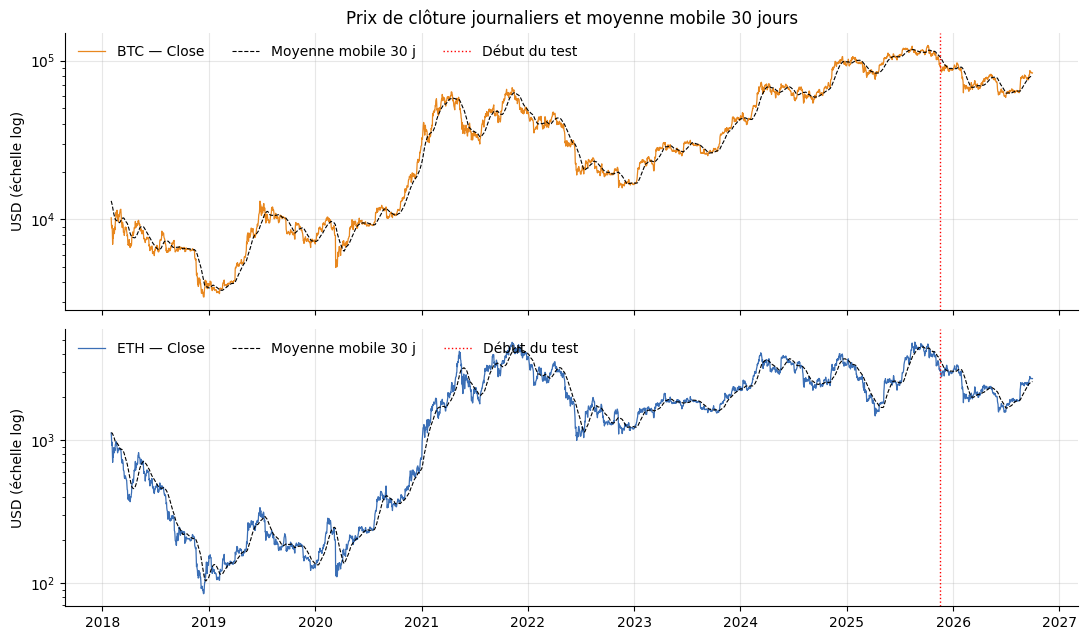

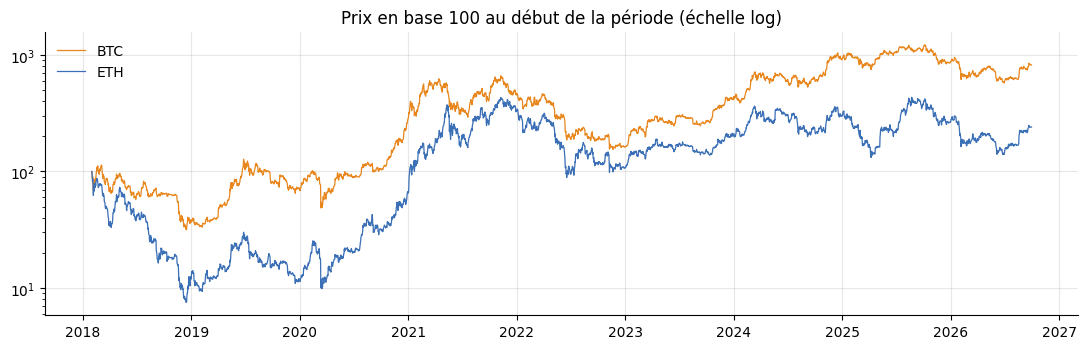

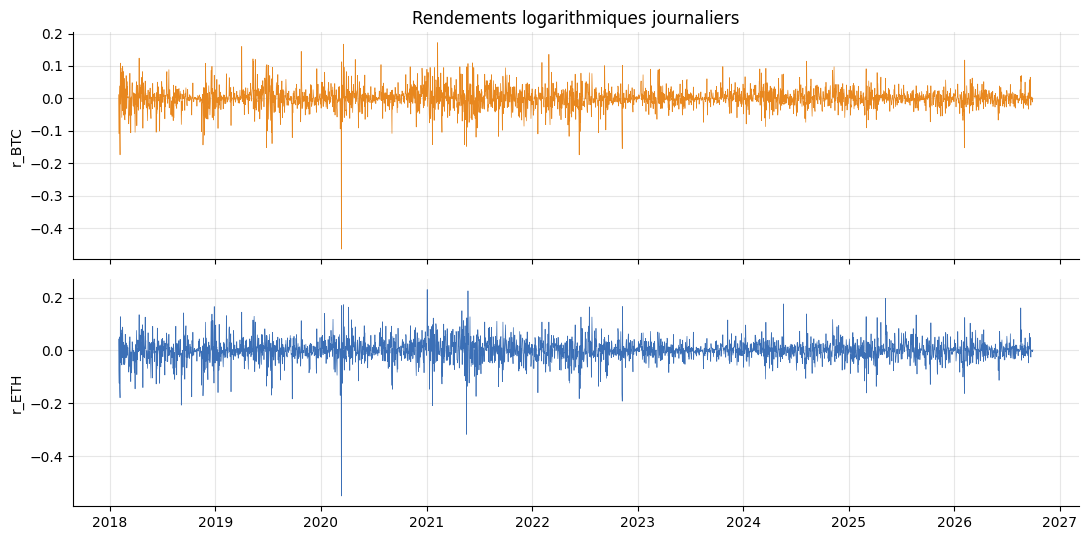

In [7]:
# Trace les prix en échelle log : une hausse de 10 % a la même hauteur quel que soit le niveau de prix.
fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for a, c, k in [("BTC", C_BTC, 0), ("ETH", C_ETH, 1)]:
    ax[k].plot(df[f"{a}_Close"], color=c, lw=0.9, label=f"{a} — Close")
    ax[k].plot(df[f"ma30_{a}"], color="black", lw=0.8, ls="--", label="Moyenne mobile 30 j")
    ax[k].axvline(date_coupe, color="red", lw=1, ls=":", label="Début du test")
    ax[k].set_yscale("log"); ax[k].set_ylabel("USD (échelle log)"); ax[k].legend(loc="upper left", ncol=3, frameon=False)
ax[0].set_title("Prix de clôture journaliers et moyenne mobile 30 jours")
sauver(fig, "01_prix")

# Ramène les deux séries à base 100 : compare des trajectoires, pas des niveaux de prix incomparables.
fig, ax = plt.subplots(figsize=(11, 3.6))
for a, c in [("BTC", C_BTC), ("ETH", C_ETH)]:
    ax.plot(100 * df[f"{a}_Close"] / df[f"{a}_Close"].iloc[0], color=c, lw=0.9, label=a)
ax.set_yscale("log"); ax.set_title("Prix en base 100 au début de la période (échelle log)"); ax.legend(frameon=False)
sauver(fig, "02_base100")

# Trace les rendements : c'est la série différenciée, celle sur laquelle porteront les tests de stationnarité.
fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for a, c, k in [("BTC", C_BTC, 0), ("ETH", C_ETH, 1)]:
    ax[k].plot(df[f"r_{a}"], color=c, lw=0.5); ax[k].set_ylabel(f"r_{a}")
ax[0].set_title("Rendements logarithmiques journaliers")
sauver(fig, "03_rendements")

In [8]:
# Calcule les statistiques sur le train uniquement : la description des données ne doit pas non plus utiliser le test.
def decrire(x):
    return {"moyenne": x.mean(), "ecart_type": x.std(), "min": x.min(), "max": x.max(),
            "skewness": stats.skew(x), "kurtosis_exces": stats.kurtosis(x)}
desc = pd.DataFrame({"BTC_Close": decrire(train["BTC_Close"]), "ETH_Close": decrire(train["ETH_Close"]),
                     "r_BTC": decrire(train["r_BTC"]), "r_ETH": decrire(train["r_ETH"])}).T
corr_rdt = float(train["r_BTC"].corr(train["r_ETH"]))
R["descriptif"] = desc.to_dict(orient="index"); R["corr_rendements"] = corr_rdt
print(f"Corrélation des rendements BTC/ETH (train) : {corr_rdt:.3f}")
print(f"Volatilité annualisée BTC : {train['r_BTC'].std() * np.sqrt(365):.1%} | ETH : {train['r_ETH'].std() * np.sqrt(365):.1%}")
table(desc, "02_statistiques_descriptives", 5)

Corrélation des rendements BTC/ETH (train) : 0.830
Volatilité annualisée BTC : 64.8% | ETH : 85.4%


,moyenne,ecart_type,min,max,skewness,kurtosis_exces
BTC_Close,36729.26600,31889.23727,3236.76172,124752.53125,1.03428,0.07275
ETH_Close,1692.05194,1303.20423,84.30830,4831.34863,0.37806,-1.01186
r_BTC,0.00078,0.03393,-0.46473,0.17182,-0.95399,15.26063
r_ETH,0.00036,0.04468,-0.55073,0.23070,-0.88822,11.41652


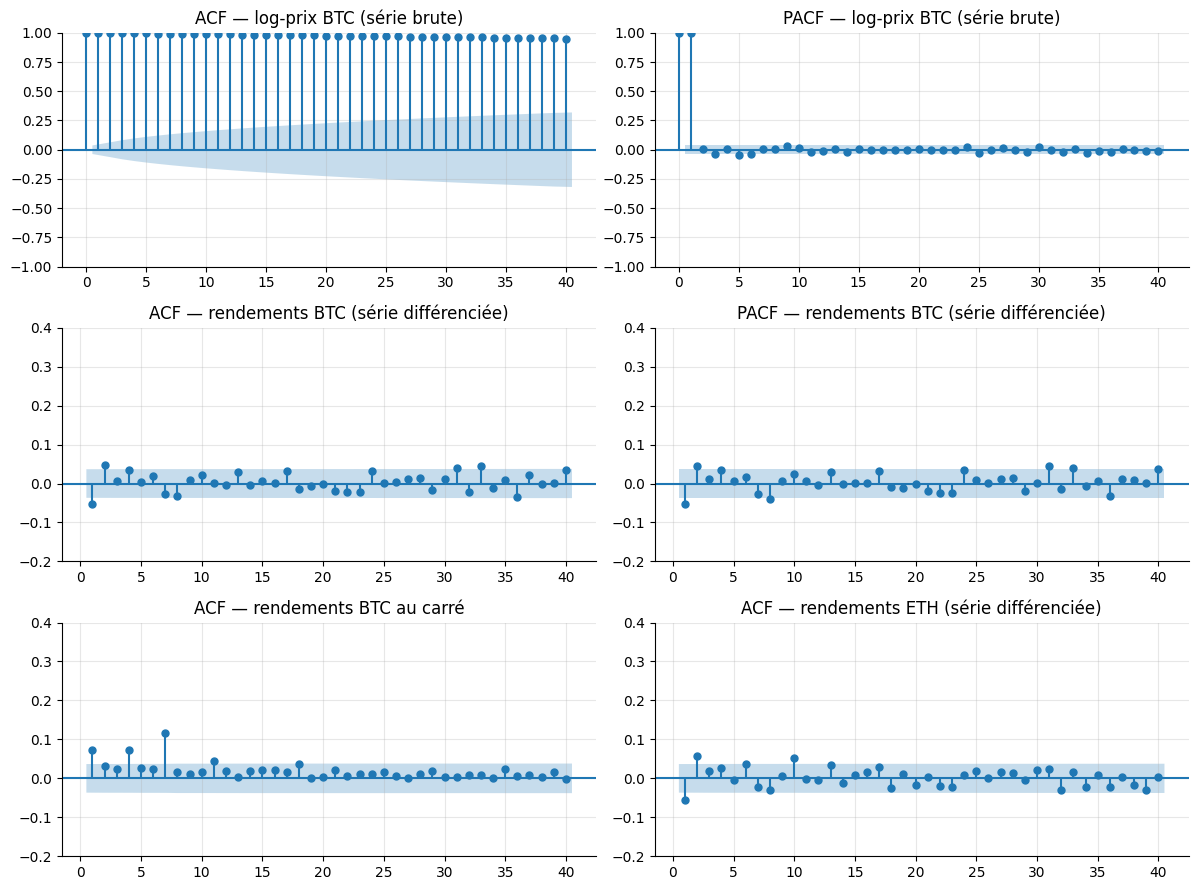

Borne de signification à 95 % : ±0.0367


,valeur_retard_1,max_abs_retards_1_20,nb_significatifs_sur_20,retards
ACF log-prix,0.998953,0.998953,20,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
ACF rendements,-0.051666,0.051666,2,"[1, 2]"
PACF rendements,-0.051666,0.051666,3,"[1, 2, 8]"
ACF rendements²,0.073065,0.115752,4,"[1, 4, 7, 11]"


In [9]:
# Trace ACF et PACF du log-prix puis des rendements : la comparaison montre l'effet de la différenciation.
LAGS = 40
fig, ax = plt.subplots(3, 2, figsize=(12, 9))
plot_acf(train["log_BTC"], lags=LAGS, ax=ax[0, 0], title="ACF — log-prix BTC (série brute)")
plot_pacf(train["log_BTC"], lags=LAGS, ax=ax[0, 1], method="ywm", title="PACF — log-prix BTC (série brute)")
plot_acf(train["r_BTC"], lags=LAGS, ax=ax[1, 0], zero=False, title="ACF — rendements BTC (série différenciée)")
plot_pacf(train["r_BTC"], lags=LAGS, ax=ax[1, 1], zero=False, method="ywm", title="PACF — rendements BTC (série différenciée)")
plot_acf(train["r_BTC"] ** 2, lags=LAGS, ax=ax[2, 0], zero=False, title="ACF — rendements BTC au carré")
plot_acf(train["r_ETH"], lags=LAGS, ax=ax[2, 1], zero=False, title="ACF — rendements ETH (série différenciée)")
for a_ in ax[1:].ravel(): a_.set_ylim(-0.2, 0.4)
sauver(fig, "04_acf_pacf")

# Compte les retards significatifs : donne un appui chiffré à l'interprétation écrite, au lieu d'une lecture « à l'œil ».
def retards_significatifs(x, nlags=20, partielle=False):
    v = pacf(x, nlags=nlags, method="ywm")[1:] if partielle else acf(x, nlags=nlags, fft=True)[1:]
    borne = 1.96 / np.sqrt(len(x))
    return [int(k + 1) for k in np.where(np.abs(v) > borne)[0]], float(v[0]), float(np.max(np.abs(v)))

lecture = {}
for nom, x, part in [("ACF log-prix", train["log_BTC"], False), ("ACF rendements", train["r_BTC"], False),
                     ("PACF rendements", train["r_BTC"], True), ("ACF rendements²", train["r_BTC"] ** 2, False)]:
    sig, v1, vmax = retards_significatifs(x, 20, part)
    lecture[nom] = {"valeur_retard_1": v1, "max_abs_retards_1_20": vmax, "nb_significatifs_sur_20": len(sig), "retards": str(sig)}
R["acf_pacf"] = lecture
print(f"Borne de signification à 95 % : ±{1.96 / np.sqrt(n_train):.4f}")
table(pd.DataFrame(lecture).T, "02_lecture_acf_pacf")

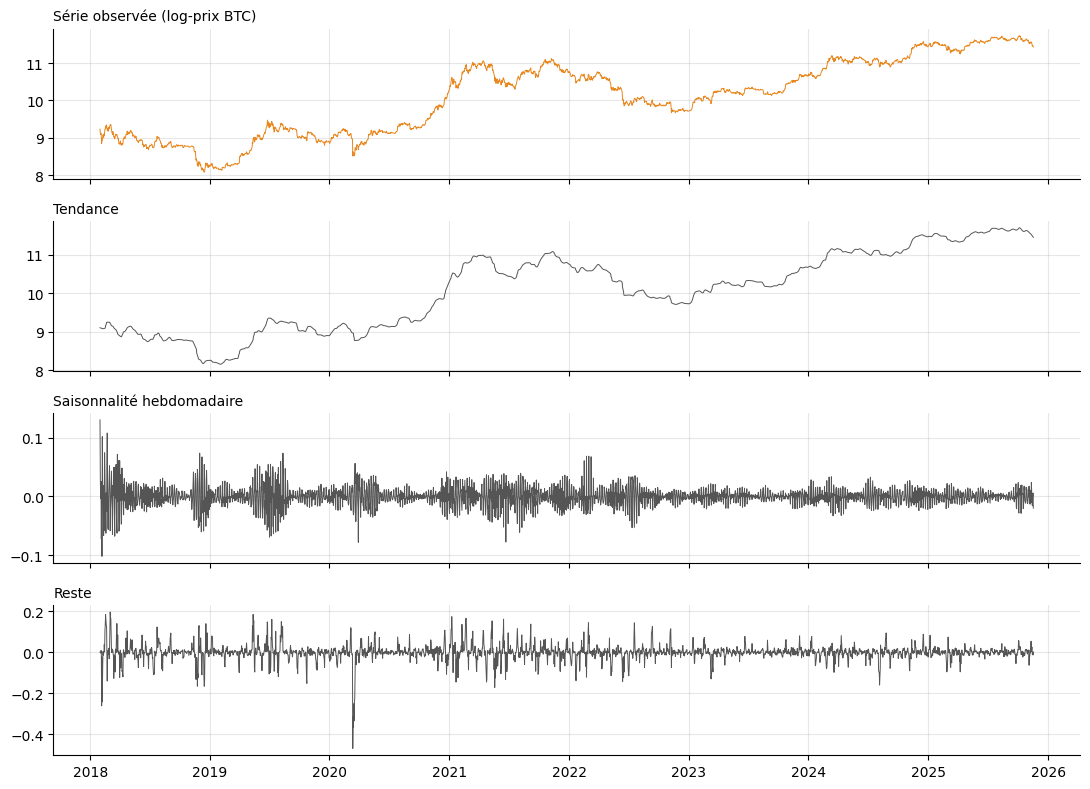

Force de la tendance      : 0.998
Force de la saisonnalité  : 0.000  (amplitude de la composante : 0.2330 en log, soit environ 23.30 %)
Kruskal-Wallis jour de la semaine : p = 0.3370 >= 0.05 : on ne rejette pas H0 (mêmes rendements les 7 jours)
→ Saisonnalité hebdomadaire retenue : NON (un SARIMA sera tout de même testé en 3.1 pour le confirmer)


,mean,std
Lundi,0.00262,0.03946
Mardi,-0.00005,0.03276
Mercredi,0.00283,0.03666
Jeudi,-0.00285,0.04241
Vendredi,0.00142,0.03291
Samedi,0.00111,0.02143
Dimanche,0.00035,0.02714


In [10]:
# Décompose le log-prix avec STL robuste, période 7 : la seule saisonnalité plausible en journalier est hebdomadaire.
stl = STL(train["log_BTC"], period=7, robust=True).fit()
fig, ax = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for k, (serie, titre) in enumerate([(train["log_BTC"], "Série observée (log-prix BTC)"), (stl.trend, "Tendance"),
                                    (stl.seasonal, "Saisonnalité hebdomadaire"), (stl.resid, "Reste")]):
    ax[k].plot(serie, color=C_BTC if k == 0 else C_GRIS, lw=0.7); ax[k].set_title(titre, loc="left", fontsize=10)
sauver(fig, "05_stl")

# Mesure la force de chaque composante : un graphique seul ne permet pas de dire si la saisonnalité est réelle.
force_saison = max(0.0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
force_tendance = max(0.0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
amplitude = float(stl.seasonal.max() - stl.seasonal.min())

# Teste l'effet « jour de la semaine » sur les rendements : Kruskal-Wallis ne suppose pas la normalité, violée ici.
groupes = [train["r_BTC"][train.index.dayofweek == j].values for j in range(7)]
kw_stat, kw_p = stats.kruskal(*groupes)
par_jour = train["r_BTC"].groupby(train.index.dayofweek).agg(["mean", "std"])
par_jour.index = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]

R["stl"] = {"force_saisonnalite": float(force_saison), "force_tendance": float(force_tendance),
            "amplitude_saisonniere_log": amplitude, "kruskal_stat": float(kw_stat), "kruskal_p": float(kw_p)}
print(f"Force de la tendance      : {force_tendance:.3f}")
print(f"Force de la saisonnalité  : {force_saison:.3f}  (amplitude de la composante : {amplitude:.4f} en log, soit environ {100 * amplitude:.2f} %)")
print("Kruskal-Wallis jour de la semaine :", verdict(kw_p, "mêmes rendements les 7 jours"))
SAISONNALITE = (force_saison > 0.10) and (kw_p < ALPHA)
print("→ Saisonnalité hebdomadaire retenue :", "OUI" if SAISONNALITE else "NON (un SARIMA sera tout de même testé en 3.1 pour le confirmer)")
table(par_jour, "02_rendement_par_jour", 5)

44 jours aberrants sur 3165 (1.39 %). Pire journée : 2020-03-12 (-46.5 %).


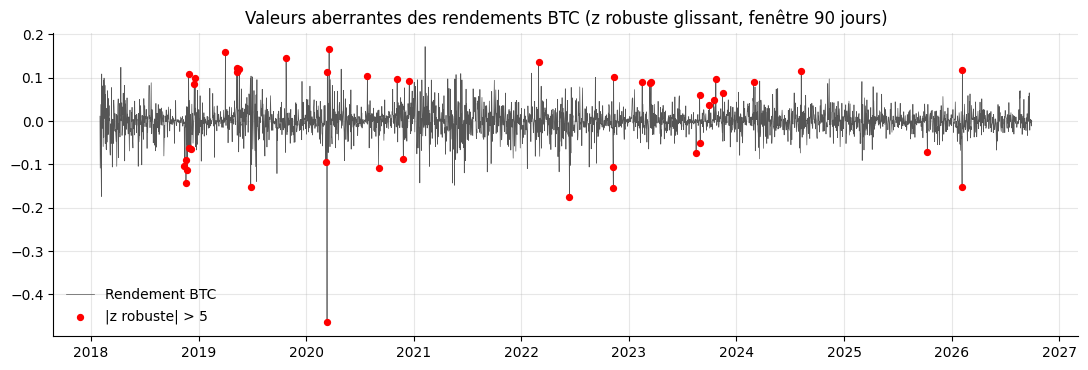

,rendement_%,z_robuste,evenement_connu
Date,,,
2020-03-12,-46.47,-26.53,Krach COVID-19
2019-04-02,16.00,16.10,
2023-10-23,9.81,13.82,
2018-11-19,-14.36,-12.12,
2018-11-24,-11.35,-9.50,
2019-05-11,12.18,9.24,
2018-11-28,10.82,9.20,
2022-11-09,-15.49,-9.07,Faillite de FTX
2018-11-14,-10.28,-8.71,


In [11]:
# Calcule un z robuste sur fenêtre passée : la médiane et le MAD ne sont pas déformés par les extrêmes qu'on cherche.
FEN = 90
r = df["r_BTC"]
med = r.rolling(FEN).median().shift(1)
mad = (r - med).abs().rolling(FEN).median().shift(1)
z_rob = (r - med) / (1.4826 * mad)
aberrants = z_rob[z_rob.abs() > 5].dropna()

# Événements connus du marché crypto : servent à vérifier que les extrêmes sont de vrais chocs et non des erreurs.
EVENEMENTS = {
    "2020-03-12": "Krach COVID-19",
    "2021-05-19": "Chute de mai 2021 (restrictions en Chine)",
    "2022-05-09": "Effondrement de Terra/Luna",
    "2022-06-13": "Gel des retraits de Celsius",
    "2022-11-08": "Faillite de FTX",
    "2024-01-10": "Approbation des ETF Bitcoin spot",
    "2024-04-20": "Halving du Bitcoin",
    "2024-08-05": "Débouclage du carry trade sur le yen",
    "2025-10-10": "Liquidations massives d'octobre 2025",
}
def evenement_proche(date, tol=3):
    for d, nom in EVENEMENTS.items():
        if abs((pd.Timestamp(d) - date).days) <= tol:
            return nom
    return ""

tab_ab = pd.DataFrame({"rendement_%": 100 * r[aberrants.index], "z_robuste": aberrants,
                       "evenement_connu": [evenement_proche(d) for d in aberrants.index]})
tab_ab = tab_ab.reindex(tab_ab["z_robuste"].abs().sort_values(ascending=False).index)
R["aberrants"] = {"nombre": int(len(aberrants)), "part_%": float(100 * len(aberrants) / N),
                  "pire_jour": str(r.idxmin().date()), "pire_rendement_%": float(100 * r.min())}
print(f"{len(aberrants)} jours aberrants sur {N} ({100 * len(aberrants) / N:.2f} %). Pire journée : {r.idxmin().date()} ({100 * r.min():.1f} %).")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(r, color=C_GRIS, lw=0.5, label="Rendement BTC")
ax.scatter(aberrants.index, r[aberrants.index], color="red", s=18, zorder=3, label="|z robuste| > 5")
ax.set_title("Valeurs aberrantes des rendements BTC (z robuste glissant, fenêtre 90 jours)"); ax.legend(frameon=False)
sauver(fig, "06_aberrants")
table(tab_ab.head(15), "02_valeurs_aberrantes", 2)

In [12]:
# Applique ADF et KPSS aux niveaux puis aux différences : leurs hypothèses nulles sont opposées, donc ils se contrôlent mutuellement.
def tests_stationnarite(x, nom, reg):
    adf_stat, adf_p, adf_lag = adfuller(x, regression=reg, autolag="AIC")[:3]
    kpss_stat, kpss_p, kpss_lag = kpss(x, regression=reg, nlags="auto")[:3]
    adf_rejette, kpss_rejette = adf_p < ALPHA, kpss_p < ALPHA
    if (not adf_rejette) and kpss_rejette: concl = "non stationnaire"
    elif adf_rejette and (not kpss_rejette): concl = "stationnaire"
    elif adf_rejette and kpss_rejette: concl = "tests en désaccord (rupture ou tendance)"
    else: concl = "non concluant"
    return {"série": nom, "spécification": reg, "ADF stat": adf_stat, "ADF p": adf_p, "ADF retards": adf_lag,
            "KPSS stat": kpss_stat, "KPSS p": kpss_p, "conclusion": concl}

lignes = []
for a in TICKERS:
    lignes.append(tests_stationnarite(train[f"log_{a}"], f"log-prix {a}", "ct"))
    lignes.append(tests_stationnarite(train[f"r_{a}"], f"rendement {a} (différence 1)", "c"))
tab_stat = pd.DataFrame(lignes).set_index("série")
R["stationnarite"] = tab_stat.to_dict(orient="index")

# Déduit l'ordre de différenciation des tests et non d'une habitude : d = 1 si le niveau est non stationnaire et la différence stationnaire.
niv, dif = tab_stat.loc["log-prix BTC", "conclusion"], tab_stat.loc["rendement BTC (différence 1)", "conclusion"]
D_ORDRE = 0 if niv == "stationnaire" else 1
R["d"] = D_ORDRE
print(f"Log-prix BTC : {niv} | Rendements BTC : {dif}")
print(f"→ Ordre de différenciation retenu : d = {D_ORDRE}" + (" (la série est intégrée d'ordre 1, notée I(1))" if D_ORDRE == 1 else ""))
if dif != "stationnaire":
    print("Attention : les deux tests ne s'accordent pas sur les rendements. Le KPSS est sensible aux changements de variance ;"
          " ce point est discuté dans le rapport.")
table(tab_stat, "02_tests_stationnarite")

Log-prix BTC : non stationnaire | Rendements BTC : stationnaire
→ Ordre de différenciation retenu : d = 1 (la série est intégrée d'ordre 1, notée I(1))


,spécification,ADF stat,ADF p,ADF retards,KPSS stat,KPSS p,conclusion
série,,,,,,,
log-prix BTC,ct,-2.1301,0.5292,4,0.4676,0.01,non stationnaire
rendement BTC (différence 1),c,-25.2596,0.0000,3,0.0978,0.10,stationnaire
log-prix ETH,ct,-2.3481,0.4076,10,0.7184,0.01,non stationnaire
rendement ETH (différence 1),c,-15.8088,0.0000,9,0.2021,0.10,stationnaire


In [13]:
# Définit les origines de prévision et la fonction d'évaluation une seule fois : tous les modèles sont jugés sur les mêmes dates.
ORIGINES = np.arange(n_train - H, N - 1)     # positions t : l'information est connue jusqu'à t inclus
CHEMINS = {}                                 # CHEMINS[modèle] : tableau (origines, H) de log-prix prévus
logp_v, prix_v = logp.values, prix.values

def extraire(chemins, h):
    """Renvoie (prévision, réel) en dollars à l'horizon h, pour les cibles situées dans l'échantillon test."""
    cibles = ORIGINES + h
    ok = (cibles >= n_train) & (cibles <= N - 1) & ~np.isnan(chemins[:, h - 1])
    idx = df.index[cibles[ok]]
    return pd.Series(np.exp(chemins[ok, h - 1]), index=idx), pd.Series(prix_v[cibles[ok]], index=idx)

def metriques(prev, reel):
    """MSE, RMSE, MAE et MAPE : les quatre métriques imposées par la section 6."""
    e = reel - prev
    return {"MSE": float(np.mean(e ** 2)), "RMSE": float(np.sqrt(np.mean(e ** 2))),
            "MAE": float(np.mean(np.abs(e))), "MAPE_%": float(100 * np.mean(np.abs(e / reel)))}

# Prévision naïve : sert de référence, car c'est la prévision optimale d'une marche aléatoire.
CHEMINS["Naïf"] = np.repeat(logp_v[ORIGINES][:, None], H, axis=1)
TEMPS["Naïf"] = 0.0
print("Origines de prévision :", len(ORIGINES), "| cibles évaluées par horizon :", len(extraire(CHEMINS["Naïf"], 1)[0]))
pd.DataFrame({f"h={h}": metriques(*extraire(CHEMINS["Naïf"], h)) for h in HORIZONS}).round(2)

Origines de prévision : 326 | cibles évaluées par horizon : 317


,h=1,h=5,h=10
MSE,3063521.12,15381181.22,35841896.82
RMSE,1750.29,3921.88,5986.81
MAE,1196.18,2779.92,4242.11
MAPE_%,1.61,3.70,5.69


In [14]:
# Ajuste les candidats « manuels » lus sur l'ACF/PACF : peu de retards significatifs → ordres 0 ou 1 seulement.
d = D_ORDRE
TENDANCES = ["n", "t"] if d == 1 else ["n", "c"]     # "t" avec d=1 correspond à une dérive (rendement moyen non nul)
NOM_T = {"n": "sans dérive", "t": "avec dérive", "c": "avec constante"}

def ajuster_arima(ordre, tendance, saison=(0, 0, 0, 0)):
    t0 = time.time()
    res = ARIMA(logp_train, order=ordre, seasonal_order=saison, trend=tendance).fit()
    return res, time.time() - t0

def ligne(ordre, tendance, res, duree):
    return {"modèle": f"ARIMA{ordre} {NOM_T[tendance]}", "ordre": ordre, "tendance": tendance, "k": len(res.params),
            "logL": res.llf, "AIC": res.aic, "BIC": res.bic, "durée_s": duree}

manuels = []
for ordre, tendance in [((0, d, 0), "n"), ((0, d, 0), TENDANCES[1]), ((1, d, 0), "n"), ((0, d, 1), "n"), ((1, d, 1), "n")]:
    res, duree = ajuster_arima(ordre, tendance)
    manuels.append(ligne(ordre, tendance, res, duree))
tab_manuel = pd.DataFrame(manuels).set_index("modèle")
table(tab_manuel.drop(columns=["ordre", "tendance"]), "03_arima_manuel", 3)

,k,logL,AIC,BIC,durée_s
modèle,,,,,
"ARIMA(0, 1, 0) sans dérive",1,5592.494,-11182.988,-11177.034,0.234
"ARIMA(0, 1, 0) avec dérive",2,5593.231,-11182.463,-11170.555,0.829
"ARIMA(1, 1, 0) sans dérive",2,5596.177,-11188.353,-11176.445,0.189
"ARIMA(0, 1, 1) sans dérive",2,5595.861,-11187.721,-11175.813,0.338
"ARIMA(1, 1, 1) sans dérive",3,5598.192,-11190.384,-11172.522,0.349


In [15]:
# Balaye toute la grille (p, q) avec et sans dérive : confirme ou contredit l'identification manuelle par un critère objectif.
grille, t_grille = [], time.time()
for p_ in range(4):
    for q_ in range(4):
        for tendance in TENDANCES:
            try:
                res, duree = ajuster_arima((p_, d, q_), tendance)
                grille.append(ligne((p_, d, q_), tendance, res, duree))
            except Exception as e:
                print("Échec", (p_, d, q_), tendance, ":", e)
tab_grille = pd.DataFrame(grille).set_index("modèle").sort_values("AIC")
print(f"{len(tab_grille)} modèles ajustés en {time.time() - t_grille:.0f} s")

meilleur_aic, meilleur_bic = tab_grille["AIC"].idxmin(), tab_grille["BIC"].idxmin()
meilleur_manuel = tab_manuel["AIC"].idxmin()
print("Meilleur selon l'AIC :", meilleur_aic)
print("Meilleur selon le BIC :", meilleur_bic)
print("Meilleur candidat manuel (AIC) :", meilleur_manuel,
      f"| écart d'AIC avec le meilleur de la grille : {tab_manuel.loc[meilleur_manuel, 'AIC'] - tab_grille['AIC'].min():.2f}")
table(tab_grille.drop(columns=["ordre", "tendance"]).head(8), "03_arima_grille", 3)

32 modèles ajustés en 31 s
Meilleur selon l'AIC : ARIMA(2, 1, 0) sans dérive
Meilleur selon le BIC : ARIMA(0, 1, 0) sans dérive
Meilleur candidat manuel (AIC) : ARIMA(1, 1, 1) sans dérive | écart d'AIC avec le meilleur de la grille : 1.75


,k,logL,AIC,BIC,durée_s
modèle,,,,,
"ARIMA(2, 1, 0) sans dérive",3,5599.065,-11192.131,-11174.268,0.246
"ARIMA(0, 1, 2) sans dérive",3,5598.951,-11191.903,-11174.041,0.144
"ARIMA(2, 1, 0) avec dérive",4,5599.810,-11191.621,-11167.805,0.486
"ARIMA(0, 1, 2) avec dérive",4,5599.700,-11191.400,-11167.584,0.309
"ARIMA(2, 1, 1) sans dérive",4,5599.629,-11191.259,-11167.443,0.268
"ARIMA(2, 1, 1) avec dérive",5,5600.323,-11190.646,-11160.876,1.547
"ARIMA(3, 1, 0) sans dérive",4,5599.278,-11190.555,-11166.739,0.806
"ARIMA(1, 1, 2) sans dérive",4,5599.215,-11190.430,-11166.614,0.393


In [16]:
# Lance pmdarima si le package fonctionne : c'est l'outil cité par le sujet, la grille ci-dessus sert de contrôle indépendant.
try:
    import pmdarima as pm
    auto = pm.auto_arima(logp_train.values, d=d, seasonal=False, max_p=3, max_q=3, stepwise=True,
                         information_criterion="aic", suppress_warnings=True, error_action="ignore")
    R["pmdarima"] = {"ordre": str(auto.order), "avec_constante": bool(auto.with_intercept), "AIC": float(auto.aic())}
    print("pmdarima (recherche pas à pas) retient : ARIMA", auto.order, "| constante :", auto.with_intercept, "| AIC = %.2f" % auto.aic())
    print("Une recherche pas à pas n'explore pas toute la grille : elle peut s'arrêter sur un modèle un peu différent du minimum global.")
except Exception as e:
    R["pmdarima"] = {"erreur": str(e)[:200]}
    print("pmdarima indisponible dans cet environnement (", type(e).__name__, "). La recherche exhaustive ci-dessus joue le même rôle.")

pmdarima (recherche pas à pas) retient : ARIMA (0, 1, 2) | constante : False | AIC = -11191.90
Une recherche pas à pas n'explore pas toute la grille : elle peut s'arrêter sur un modèle un peu différent du minimum global.


In [17]:
# Ajoute une composante saisonnière de période 7 au modèle retenu : vérifie par l'AIC que la saisonnalité est bien inutile.
ORDRE = tab_grille.loc[meilleur_aic, "ordre"]; TENDANCE = tab_grille.loc[meilleur_aic, "tendance"]
arima_fin, duree_arima = ajuster_arima(ORDRE, TENDANCE)
sarima, duree_sarima = ajuster_arima(ORDRE, TENDANCE, saison=(1, 0, 1, 7))
tab_sarima = pd.DataFrame({
    f"ARIMA{ORDRE}": {"k": len(arima_fin.params), "AIC": arima_fin.aic, "BIC": arima_fin.bic},
    f"SARIMA{ORDRE}(1,0,1)[7]": {"k": len(sarima.params), "AIC": sarima.aic, "BIC": sarima.bic}}).T
p_saison = sarima.pvalues[[n for n in sarima.pvalues.index if "S.L7" in n]]
gain = arima_fin.aic - sarima.aic
SARIMA_UTILE = (gain > 2) and (sarima.bic < arima_fin.bic)
print(f"Gain d'AIC apporté par la saisonnalité : {gain:.2f} | p-values des coefficients saisonniers : {p_saison.round(4).to_dict()}")
print("→", "La composante saisonnière améliore le modèle : SARIMA retenu." if SARIMA_UTILE
      else "La composante saisonnière n'améliore pas le modèle : on garde l'ARIMA non saisonnier.")
if SARIMA_UTILE:
    arima_fin, duree_arima = sarima, duree_sarima
NOM_ARIMA = ("S" if SARIMA_UTILE else "") + f"ARIMA{ORDRE}" + ("(1,0,1)[7]" if SARIMA_UTILE else "")
R["arima"] = {"retenu": NOM_ARIMA, "tendance": NOM_T[TENDANCE], "meilleur_AIC": meilleur_aic, "meilleur_BIC": meilleur_bic,
              "meilleur_manuel": meilleur_manuel, "AIC": float(arima_fin.aic), "BIC": float(arima_fin.bic),
              "gain_AIC_saisonnalite": float(gain), "sarima_utile": bool(SARIMA_UTILE),
              "coefficients": arima_fin.params.to_dict(), "p_values": arima_fin.pvalues.to_dict()}
table(tab_sarima, "03_arima_vs_sarima", 3)

Gain d'AIC apporté par la saisonnalité : -1.87 | p-values des coefficients saisonniers : {'ar.S.L7': 0.5931, 'ma.S.L7': 0.5645}
→ La composante saisonnière n'améliore pas le modèle : on garde l'ARIMA non saisonnier.


,k,AIC,BIC
"ARIMA(2, 1, 0)",3.0,-11192.131,-11174.268
"SARIMA(2, 1, 0)(1,0,1)[7]",5.0,-11190.264,-11160.494


In [18]:
# Affiche les coefficients du modèle retenu : un coefficient non significatif signale un terme superflu.
print("Modèle retenu :", NOM_ARIMA, NOM_T[TENDANCE])
print(arima_fin.summary().tables[1])

Modèle retenu : ARIMA(2, 1, 0) sans dérive
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0499      0.013     -3.736      0.000      -0.076      -0.024
ar.L2          0.0450      0.016      2.794      0.005       0.013       0.077
sigma2         0.0011   1.03e-05    110.881      0.000       0.001       0.001


 Indépendance  : p = 0.1277 >= 0.05 : on ne rejette pas H0 (résidus non autocorrélés)
 Normalité     : p = 0.0000 < 0.05 : on rejette H0 (résidus normaux) | kurtosis = 18.4 (3 pour une loi normale)
 Homoscédasticité : p = 0.0000 < 0.05 : on rejette H0 (pas d'effet ARCH)


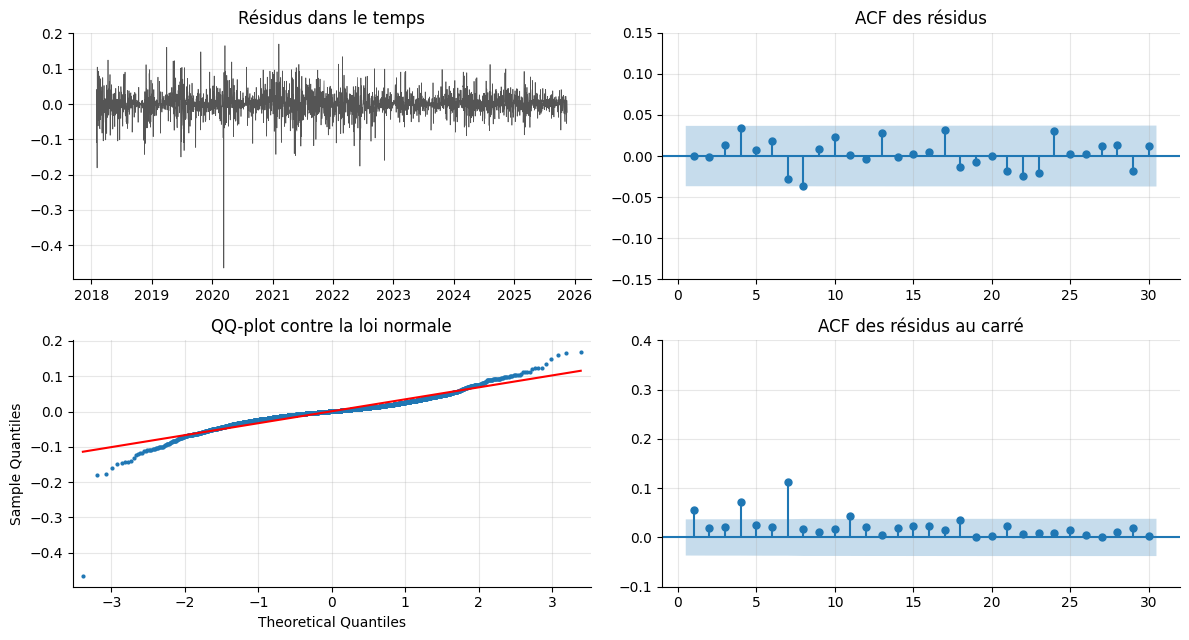

série,"ARIMA(2, 1, 0)"
Ljung-Box(10) p,0.1277
Ljung-Box(20) p,0.4163
Jarque-Bera p,0.0000
skewness,-0.9763
kurtosis,18.3980
ARCH-LM(10) p,0.0000
Ljung-Box résidus²(10) p,0.0000


In [19]:
# Regroupe les trois tests de résidus dans une fonction : le même diagnostic complet sera appliqué à ARIMA, VAR et GARCH.
def diagnostic(residus, nom, ddl=0):
    e = pd.Series(np.asarray(residus, dtype=float)).dropna()
    lb = acorr_ljungbox(e, lags=[10, 20], model_df=ddl, return_df=True)
    lb2 = acorr_ljungbox(e ** 2, lags=[10], return_df=True)
    jb_stat, jb_p, sk, ku = jarque_bera(e)
    lm_stat, lm_p, _, _ = het_arch(e, nlags=10)
    return {"série": nom, "Ljung-Box(10) p": float(lb["lb_pvalue"].iloc[0]), "Ljung-Box(20) p": float(lb["lb_pvalue"].iloc[1]),
            "Jarque-Bera p": float(jb_p), "skewness": float(sk), "kurtosis": float(ku),
            "ARCH-LM(10) p": float(lm_p), "Ljung-Box résidus²(10) p": float(lb2["lb_pvalue"].iloc[0])}

def conclure_diagnostic(dg):
    print(" Indépendance  :", verdict(dg["Ljung-Box(10) p"], "résidus non autocorrélés"))
    print(" Normalité     :", verdict(dg["Jarque-Bera p"], "résidus normaux"), f"| kurtosis = {dg['kurtosis']:.1f} (3 pour une loi normale)")
    print(" Homoscédasticité :", verdict(dg["ARCH-LM(10) p"], "pas d'effet ARCH"))

# Écarte les d premiers résidus : ils correspondent à l'initialisation de la différenciation, pas à une erreur de prévision.
res_arima = arima_fin.resid.iloc[max(d, 1):]
diag_arima = diagnostic(res_arima, NOM_ARIMA, ddl=ORDRE[0] + ORDRE[2])
R["diag_arima"] = diag_arima
conclure_diagnostic(diag_arima)

fig, ax = plt.subplots(2, 2, figsize=(12, 6.5))
ax[0, 0].plot(res_arima, color=C_GRIS, lw=0.5); ax[0, 0].set_title("Résidus dans le temps")
plot_acf(res_arima, lags=30, ax=ax[0, 1], zero=False, title="ACF des résidus"); ax[0, 1].set_ylim(-0.15, 0.15)
sm.qqplot(res_arima, line="s", ax=ax[1, 0], markersize=2); ax[1, 0].set_title("QQ-plot contre la loi normale")
plot_acf(res_arima ** 2, lags=30, ax=ax[1, 1], zero=False, title="ACF des résidus au carré"); ax[1, 1].set_ylim(-0.1, 0.4)
sauver(fig, "07_diagnostic_arima")
table(pd.DataFrame([diag_arima]).set_index("série").T, "03_diagnostic_arima")

In [20]:
# Réapplique les paramètres estimés sur le train à chaque origine, sans réestimation : aucune donnée de test n'influence les coefficients.
t0 = time.time()
ch = np.empty((len(ORIGINES), H))
for i, t in enumerate(ORIGINES):
    ch[i] = np.asarray(arima_fin.apply(logp.iloc[:t + 1]).forecast(H))
CHEMINS["ARIMA"] = ch
TEMPS["ARIMA"] = duree_arima
print(f"Prévisions glissantes ARIMA calculées en {time.time() - t0:.0f} s")

# Prévision à 10 jours depuis la fin du train, avec intervalle à 95 % : exigence de la section 6.
prev_fixe = arima_fin.get_forecast(H).summary_frame(alpha=ALPHA)
ic_arima = np.exp(prev_fixe[["mean", "mean_ci_lower", "mean_ci_upper"]])
ic_arima.columns = ["prévision", "borne_basse_95", "borne_haute_95"]
ic_arima["réel"] = prix.iloc[n_train:n_train + H].values
ic_arima["dans_intervalle"] = (ic_arima["réel"] >= ic_arima["borne_basse_95"]) & (ic_arima["réel"] <= ic_arima["borne_haute_95"])
table(ic_arima, "03_arima_prevision_10j", 0)

Prévisions glissantes ARIMA calculées en 10 s


,prévision,borne_basse_95,borne_haute_95,réel,dans_intervalle
2025-11-18,92137.0,86221.0,98458.0,92949.0,True
2025-11-19,92042.0,83991.0,100864.0,91466.0,True
2025-11-20,92049.0,82217.0,103056.0,86632.0,True
2025-11-21,92044.0,80761.0,104903.0,85091.0,True
2025-11-22,92045.0,79501.0,106567.0,84648.0,True
2025-11-23,92044.0,78381.0,108090.0,86805.0,True
2025-11-24,92044.0,77366.0,109508.0,88271.0,True
2025-11-25,92044.0,76433.0,110844.0,87342.0,True
2025-11-26,92044.0,75568.0,112113.0,90518.0,True
2025-11-27,92044.0,74760.0,113326.0,91285.0,True


In [21]:
# Estime le VAR sur les rendements et non sur les prix : le VAR suppose des séries stationnaires.
VARS = ["r_BTC", "r_ETH"]
selection = VAR(train[VARS]).select_order(maxlags=14)
print(selection.summary())
p_aic, p_bic = selection.selected_orders["aic"], selection.selected_orders["bic"]
P_VAR = max(1, p_aic)
print(f"\nOrdre choisi par l'AIC : {p_aic} | par le BIC : {p_bic} → ordre retenu : p = {P_VAR}")

t0 = time.time()
var_fin = VAR(train[VARS]).fit(P_VAR)
TEMPS["VAR"] = time.time() - t0
print("Le VAR est stable (toutes les racines hors du cercle unité) :", var_fin.is_stable())
coef_var = pd.DataFrame({"coefficient": var_fin.params["r_BTC"], "p_value": var_fin.pvalues["r_BTC"]})
print("\nÉquation du rendement BTC :")
table(coef_var, "03_var_equation_btc")

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -14.18     -14.17*   6.952e-07      -14.18
1       -14.18      -14.17   6.920e-07     -14.18*
2       -14.18      -14.16   6.915e-07      -14.18
3       -14.18      -14.16   6.912e-07      -14.17
4      -14.19*      -14.15  6.890e-07*      -14.17
5       -14.19      -14.14   6.897e-07      -14.17
6       -14.19      -14.13   6.895e-07      -14.17
7       -14.19      -14.13   6.890e-07      -14.17
8       -14.19      -14.12   6.896e-07      -14.16
9       -14.18      -14.10   6.915e-07      -14.16
10      -14.19      -14.10   6.904e-07      -14.15
11      -14.18      -14.09   6.922e-07      -14.15
12      -14.18      -14.08   6.940e-07      -14.14
13      -14.18      -14.07   6.945e-07      -14.14
14      -14.18      -14.06   6.962e-07      -14.13
--------------------------------------------------

Ordre choisi par l'AIC : 4 | p

,coefficient,p_value
const,0.0008,0.2230
L1.r_BTC,0.0115,0.7323
L1.r_ETH,-0.0558,0.0292
L2.r_BTC,0.0242,0.4725
L2.r_ETH,0.0165,0.5191
L3.r_BTC,0.0443,0.1872
L3.r_ETH,-0.0257,0.3136
L4.r_BTC,-0.0269,0.4228
L4.r_ETH,0.0578,0.0234


In [22]:
# Diagnostique les résidus du VAR avec la même fonction que l'ARIMA : un modèle sans diagnostic n'est pas noté.
blancheur = var_fin.test_whiteness(nlags=max(10, P_VAR + 5), adjusted=True)
print("Portemanteau multivarié :", verdict(blancheur.pvalue, "résidus du système non autocorrélés"))
diag_var = [diagnostic(var_fin.resid[v], f"VAR({P_VAR}) — équation {v}") for v in VARS]
for dg in diag_var:
    print("\n" + dg["série"]); conclure_diagnostic(dg)
corr_res = float(var_fin.resid.corr().iloc[0, 1])
print(f"\nCorrélation des résidus des deux équations : {corr_res:.3f}")
R["var"] = {"p_aic": int(p_aic), "p_bic": int(p_bic), "p_retenu": int(P_VAR), "stable": bool(var_fin.is_stable()),
            "portemanteau_p": float(blancheur.pvalue), "corr_residus": corr_res,
            "coef_btc": coef_var.to_dict(orient="index"), "diagnostic": diag_var}
table(pd.DataFrame(diag_var).set_index("série").T, "03_diagnostic_var")

Portemanteau multivarié : p = 0.0095 < 0.05 : on rejette H0 (résidus du système non autocorrélés)

VAR(4) — équation r_BTC
 Indépendance  : p = 0.5794 >= 0.05 : on ne rejette pas H0 (résidus non autocorrélés)
 Normalité     : p = 0.0000 < 0.05 : on rejette H0 (résidus normaux) | kurtosis = 18.0 (3 pour une loi normale)
 Homoscédasticité : p = 0.0000 < 0.05 : on rejette H0 (pas d'effet ARCH)

VAR(4) — équation r_ETH
 Indépendance  : p = 0.0526 >= 0.05 : on ne rejette pas H0 (résidus non autocorrélés)
 Normalité     : p = 0.0000 < 0.05 : on rejette H0 (résidus normaux) | kurtosis = 14.3 (3 pour une loi normale)
 Homoscédasticité : p = 0.0000 < 0.05 : on rejette H0 (pas d'effet ARCH)

Corrélation des résidus des deux équations : 0.831


série,VAR(4) — équation r_BTC,VAR(4) — équation r_ETH
Ljung-Box(10) p,0.5794,0.0526
Ljung-Box(20) p,0.7994,0.1052
Jarque-Bera p,0.0000,0.0000
skewness,-0.9461,-0.8698
kurtosis,17.9571,14.2645
ARCH-LM(10) p,0.0000,0.0000
Ljung-Box résidus²(10) p,0.0000,0.0000


In [23]:
# Teste la causalité dans les deux sens : savoir si ETH aide à prévoir BTC est la question centrale du projet.
g1 = var_fin.test_causality(caused="r_BTC", causing="r_ETH", kind="f")
g2 = var_fin.test_causality(caused="r_ETH", causing="r_BTC", kind="f")
inst = var_fin.test_inst_causality(causing="r_ETH")
tab_granger = pd.DataFrame([
    {"hypothèse nulle": "ETH ne cause pas BTC (Granger)", "statistique": g1.test_statistic, "p_value": g1.pvalue},
    {"hypothèse nulle": "BTC ne cause pas ETH (Granger)", "statistique": g2.test_statistic, "p_value": g2.pvalue},
    {"hypothèse nulle": "Pas de causalité instantanée", "statistique": inst.test_statistic, "p_value": inst.pvalue},
]).set_index("hypothèse nulle")
tab_granger["décision"] = np.where(tab_granger["p_value"] < ALPHA, "H0 rejetée", "H0 non rejetée")
R["granger"] = tab_granger.to_dict(orient="index")
print("ETH → BTC :", verdict(g1.pvalue, "ETH ne cause pas BTC"))
print("BTC → ETH :", verdict(g2.pvalue, "BTC ne cause pas ETH"))
print("Lien instantané :", verdict(inst.pvalue, "pas de lien le jour même"))
table(tab_granger, "03_granger")

ETH → BTC : p = 0.0249 < 0.05 : on rejette H0 (ETH ne cause pas BTC)
BTC → ETH : p = 0.2771 >= 0.05 : on ne rejette pas H0 (BTC ne cause pas ETH)
Lien instantané : p = 0.0000 < 0.05 : on rejette H0 (pas de lien le jour même)


,statistique,p_value,décision
hypothèse nulle,,,
ETH ne cause pas BTC (Granger),2.7900,0.0249,H0 rejetée
BTC ne cause pas ETH (Granger),1.2757,0.2771,H0 non rejetée
Pas de causalité instantanée,1161.0035,0.0000,H0 rejetée


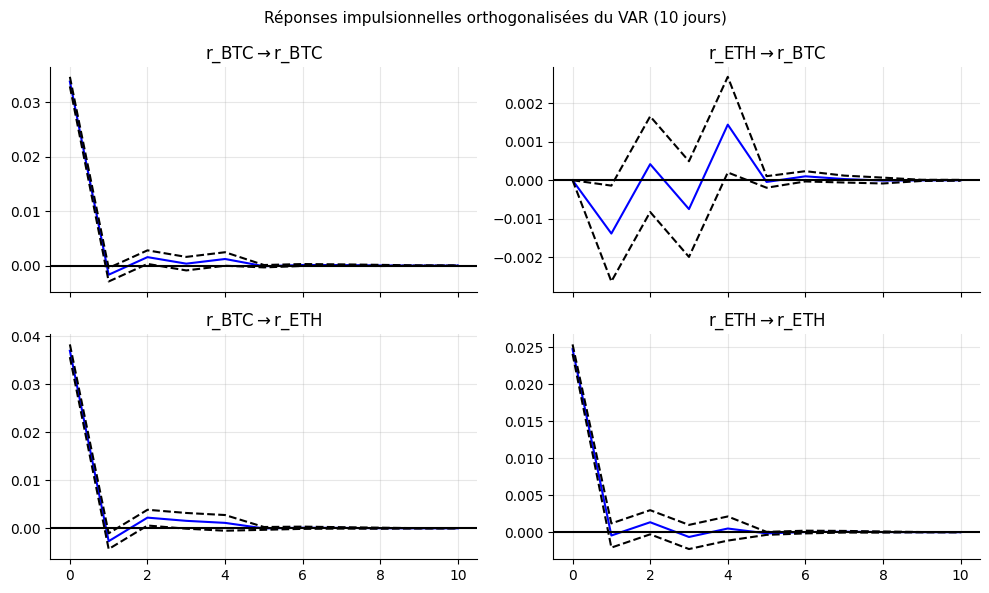

In [24]:
# Trace les réponses impulsionnelles : montre combien de jours un choc sur un actif se propage à l'autre.
fig = var_fin.irf(10).plot(orth=True, figsize=(10, 6))
fig.suptitle("Réponses impulsionnelles orthogonalisées du VAR (10 jours)", fontsize=11)
sauver(fig, "08_var_irf")

# Prévision glissante : le VAR prévoit des rendements, qu'on cumule pour revenir au log-prix.
rv = df[VARS].values
ch = np.empty((len(ORIGINES), H))
for i, t in enumerate(ORIGINES):
    prev_r = var_fin.forecast(rv[t - P_VAR + 1:t + 1], steps=H)
    ch[i] = logp_v[t] + np.cumsum(prev_r[:, 0])
CHEMINS["VAR"] = ch

Engle-Granger (BTC expliqué par ETH) : p = 0.4053 >= 0.05 : on ne rejette pas H0 (pas de cointégration)
Engle-Granger (ETH expliqué par BTC) : p = 0.4009 >= 0.05 : on ne rejette pas H0 (pas de cointégration)

Johansen (k_ar_diff = 7) : rang de cointégration estimé r = 0
→ Pas de cointégration au seuil de 5 % : le VAR en différences est le bon modèle, un VECM n'est pas justifié.


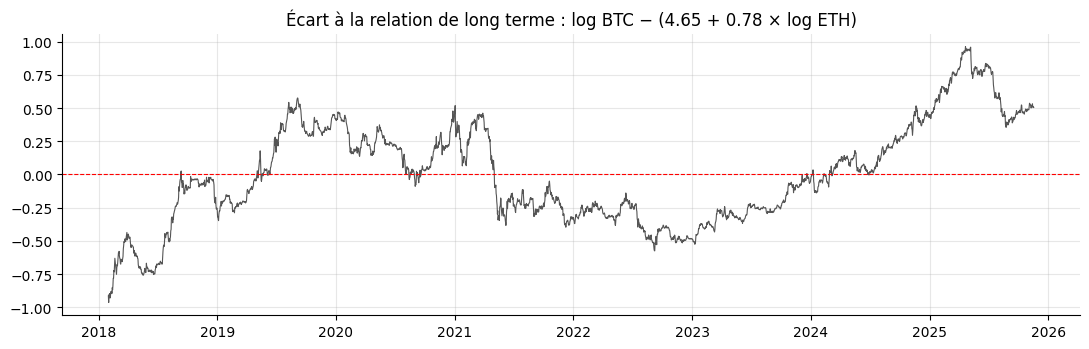

,statistique de la trace,valeur critique 5 %,valeur propre max,valeur critique 5 % (max),décision (trace)
H0 : r = 0,8.536,15.494,7.145,14.264,H0 non rejetée
H0 : r <= 1,1.390,3.842,1.390,3.842,H0 non rejetée


In [25]:
# Teste la cointégration sur les log-prix (niveaux I(1)) : c'est ce qui décide entre VAR en différences et VECM.
NIV = ["log_BTC", "log_ETH"]
niveaux = train[NIV]

# Engle-Granger dans les deux sens : le test dépend de la variable placée à gauche de la régression.
eg1_stat, eg1_p, _ = coint(niveaux["log_BTC"], niveaux["log_ETH"], trend="c", autolag="aic")
eg2_stat, eg2_p, _ = coint(niveaux["log_ETH"], niveaux["log_BTC"], trend="c", autolag="aic")
print("Engle-Granger (BTC expliqué par ETH) :", verdict(eg1_p, "pas de cointégration"))
print("Engle-Granger (ETH expliqué par BTC) :", verdict(eg2_p, "pas de cointégration"))

# Johansen : le nombre de retards en différences est celui du VAR en niveaux moins un (lien entre les deux écritures).
p_niv = max(1, VAR(niveaux).select_order(maxlags=10).selected_orders["aic"])
K_DIFF = p_niv - 1
joh = coint_johansen(niveaux, det_order=0, k_ar_diff=K_DIFF)
tab_joh = pd.DataFrame({"statistique de la trace": joh.lr1, "valeur critique 5 %": joh.cvt[:, 1],
                        "valeur propre max": joh.lr2, "valeur critique 5 % (max)": joh.cvm[:, 1]},
                       index=["H0 : r = 0", "H0 : r <= 1"])
tab_joh["décision (trace)"] = np.where(tab_joh["statistique de la trace"] > tab_joh["valeur critique 5 %"], "H0 rejetée", "H0 non rejetée")
RANG = 0
for i in range(2):                       # procédure séquentielle : on s'arrête au premier H0 non rejeté
    if joh.lr1[i] > joh.cvt[i, 1]: RANG = i + 1
    else: break
COINTEGRE = (RANG == 1)
print(f"\nJohansen (k_ar_diff = {K_DIFF}) : rang de cointégration estimé r = {RANG}")
if RANG == 2:
    print("r = 2 signifierait que les deux séries sont stationnaires, ce qui contredit la section 2.6 : résultat à ne pas retenir.")
print("→", "Cointégration détectée : on estime un VECM." if COINTEGRE
      else "Pas de cointégration au seuil de 5 % : le VAR en différences est le bon modèle, un VECM n'est pas justifié.")

# Trace l'écart à la relation de long terme : s'il dérive sans revenir vers zéro, il n'y a visiblement pas d'équilibre stable.
mco = sm.OLS(niveaux["log_BTC"], sm.add_constant(niveaux["log_ETH"])).fit()
ecart = mco.resid
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(ecart, color=C_GRIS, lw=0.8); ax.axhline(0, color="red", lw=0.8, ls="--")
ax.set_title(f"Écart à la relation de long terme : log BTC − ({mco.params.iloc[0]:.2f} + {mco.params.iloc[1]:.2f} × log ETH)")
sauver(fig, "09_ecart_cointegration")
R["cointegration"] = {"EG_BTC_sur_ETH_p": float(eg1_p), "EG_ETH_sur_BTC_p": float(eg2_p), "k_ar_diff": int(K_DIFF),
                      "trace": [float(x) for x in joh.lr1], "critique_5": [float(x) for x in joh.cvt[:, 1]],
                      "rang": int(RANG), "cointegre": bool(COINTEGRE), "beta_MCO": float(mco.params.iloc[1]),
                      "ADF_ecart_p": float(adfuller(ecart, regression="c")[1])}
table(tab_joh, "03_johansen", 3)

In [26]:
# N'estime le VECM que si la cointégration est détectée : l'appliquer sans relation d'équilibre serait une erreur de spécification.
if COINTEGRE:
    t0 = time.time()
    vecm = VECM(niveaux, k_ar_diff=K_DIFF, coint_rank=1, deterministic="co").fit()
    TEMPS["VECM"] = time.time() - t0
    alpha_, beta_ = vecm.alpha[:, 0], vecm.beta[:, 0]
    rappel = float(alpha_ @ beta_)
    demi_vie = float(np.log(0.5) / np.log(1 + rappel)) if -1 < rappel < 0 else float("nan")
    tab_vecm = pd.DataFrame({"beta (long terme)": beta_, "alpha (ajustement)": alpha_, "p_value alpha": vecm.pvalues_alpha[:, 0]}, index=NIV)
    print(f"Demi-vie d'un écart à l'équilibre : {demi_vie:.0f} jours")
    for v, a_, p_ in zip(NIV, alpha_, vecm.pvalues_alpha[:, 0]):
        print(f" {v} : alpha = {a_:.4f} →", "s'ajuste vers l'équilibre" if p_ < ALPHA else "ne s'ajuste pas (faiblement exogène)")

    # Écrit le VECM comme un VAR en niveaux pour le réappliquer à chaque origine avec des paramètres figés.
    A_, c_ = vecm.var_rep, np.asarray(vecm.det_coef)[:, 0]
    k_ar = A_.shape[0]
    def prevoir_vecm(historique, pas):
        h_ = [x for x in historique[-k_ar:]]
        for _ in range(pas):
            h_.append(c_ + sum(A_[j] @ h_[-1 - j] for j in range(k_ar)))
        return np.array(h_[k_ar:])
    # Contrôle la réécriture contre la prévision native de statsmodels : garantit que la formule manuelle est exacte.
    ecart_controle = float(np.abs(prevoir_vecm(niveaux.values, H) - vecm.predict(steps=H)).max())
    print(f"Contrôle de la réécriture VAR du VECM : écart maximal = {ecart_controle:.2e}")
    if ecart_controle < 1e-6:
        nv = df[NIV].values
        CHEMINS["VECM"] = np.array([prevoir_vecm(nv[:t + 1], H)[:, 0] for t in ORIGINES])
    else:
        print("Réécriture non conforme : le VECM est exclu de la comparaison glissante pour ne pas publier de prévisions fausses.")
    diag_vecm = [diagnostic(vecm.resid[:, j], f"VECM — équation {v}") for j, v in enumerate(NIV)]
    R["vecm"] = {"alpha": alpha_.tolist(), "beta": beta_.tolist(), "p_alpha": vecm.pvalues_alpha[:, 0].tolist(),
                 "demi_vie_jours": demi_vie, "diagnostic": diag_vecm}
    display(table(tab_vecm, "03_vecm"))
    display(table(pd.DataFrame(diag_vecm).set_index("série").T, "03_diagnostic_vecm"))
else:
    R["vecm"] = {"estime": False, "raison": "pas de cointégration détectée au seuil de 5 %"}
    print("VECM non estimé : aucune relation de cointégration n'a été détectée.")
    print("C'est un résultat en soi : sur cette période, le Bitcoin et l'Ethereum sont fortement corrélés à court terme")
    print("mais ne partagent pas d'équilibre de long terme stable. Le VAR en différences reste le modèle multivarié retenu.")

VECM non estimé : aucune relation de cointégration n'a été détectée.
C'est un résultat en soi : sur cette période, le Bitcoin et l'Ethereum sont fortement corrélés à court terme
mais ne partagent pas d'équilibre de long terme stable. Le VAR en différences reste le modèle multivarié retenu.


In [27]:
# Vérifie l'effet ARCH sur les résidus du meilleur ARIMA à plusieurs retards : c'est la condition qui justifie d'estimer un GARCH.
arch_tests = {f"{k} retards": het_arch(res_arima, nlags=k)[:2] for k in [1, 5, 10, 20]}
tab_arch = pd.DataFrame(arch_tests, index=["statistique LM", "p_value"]).T
EFFET_ARCH = bool(tab_arch.loc["10 retards", "p_value"] < ALPHA)
R["arch_lm_arima"] = tab_arch.to_dict(orient="index")
print("ARCH-LM sur les résidus de", NOM_ARIMA, ":", verdict(tab_arch.loc["10 retards", "p_value"], "pas d'effet ARCH"))
print("→", "Effet ARCH présent : un modèle GARCH est justifié." if EFFET_ARCH else "Pas d'effet ARCH détecté : le GARCH est estimé à titre de vérification.")
table(tab_arch, "03_arch_lm")

ARCH-LM sur les résidus de ARIMA(2, 1, 0) : p = 0.0000 < 0.05 : on rejette H0 (pas d'effet ARCH)
→ Effet ARCH présent : un modèle GARCH est justifié.


,statistique LM,p_value
1 retards,8.9816,0.0027
5 retards,22.1290,0.0005
10 retards,55.2149,0.0000
20 retards,58.6053,0.0000


In [28]:
# Compare plusieurs spécifications : le GARCH(1,1) est la référence, les autres ne sont retenues que si le BIC le justifie.
r_pct_train = 100 * train["r_BTC"]
SPECS = {
    "GARCH(1,1) normale":     dict(vol="GARCH", p=1, o=0, q=1, dist="normal"),
    "GARCH(1,1) Student":     dict(vol="GARCH", p=1, o=0, q=1, dist="t"),
    "GARCH(2,1) Student":     dict(vol="GARCH", p=2, o=0, q=1, dist="t"),
    "GARCH(1,2) Student":     dict(vol="GARCH", p=1, o=0, q=2, dist="t"),
    "GJR-GARCH(1,1) Student": dict(vol="GARCH", p=1, o=1, q=1, dist="t"),
    "EGARCH(1,1) Student":    dict(vol="EGARCH", p=1, o=1, q=1, dist="t"),
}
garchs, lignes = {}, []
for nom, spec in SPECS.items():
    t0 = time.time()
    g = arch_model(r_pct_train, mean="Constant", **spec).fit(disp="off")
    garchs[nom] = g
    par = g.params
    # Persistance : alpha + beta (+ gamma/2 pour GJR) ; pour l'EGARCH, c'est le coefficient beta seul.
    if spec["vol"] == "EGARCH":
        persistance = float(sum(v for k, v in par.items() if k.startswith("beta")))
    else:
        persistance = float(sum(v for k, v in par.items() if k.startswith(("alpha", "beta")))
                            + 0.5 * sum(v for k, v in par.items() if k.startswith("gamma")))
    z = g.std_resid.dropna()
    lignes.append({"modèle": nom, "k": len(par), "logL": g.loglikelihood, "AIC": g.aic, "BIC": g.bic, "persistance": persistance,
                   "LB z (10) p": float(acorr_ljungbox(z, lags=[10], return_df=True)["lb_pvalue"].iloc[0]),
                   "LB z² (10) p": float(acorr_ljungbox(z ** 2, lags=[10], return_df=True)["lb_pvalue"].iloc[0]),
                   "ARCH-LM z (10) p": float(het_arch(z, nlags=10)[1]), "durée_s": time.time() - t0})
tab_garch = pd.DataFrame(lignes).set_index("modèle")
NOM_GARCH = tab_garch["BIC"].idxmin()
garch_fin = garchs[NOM_GARCH]
TEMPS["GARCH"] = float(tab_garch.loc[NOM_GARCH, "durée_s"])
print("Modèle de volatilité retenu (BIC minimal) :", NOM_GARCH)
table(tab_garch, "03_garch_comparaison")

Modèle de volatilité retenu (BIC minimal) : EGARCH(1,1) Student


,k,logL,AIC,BIC,persistance,LB z (10) p,LB z² (10) p,ARCH-LM z (10) p,durée_s
modèle,,,,,,,,,
"GARCH(1,1) normale",4,-7341.0544,14690.1088,14713.9263,0.9544,0.3604,0.8467,0.8497,0.0332
"GARCH(1,1) Student",5,-6994.0397,13998.0793,14027.8512,1.0000,0.2371,0.9021,0.9011,0.0603
"GARCH(2,1) Student",6,-6994.0397,14000.0793,14035.8056,1.0000,0.2371,0.9021,0.9011,0.0800
"GARCH(1,2) Student",6,-6993.0001,13998.0001,14033.7263,1.0000,0.2429,0.9169,0.9152,0.0811
"GJR-GARCH(1,1) Student",6,-6994.0082,14000.0164,14035.7427,1.0000,0.2331,0.9005,0.8997,0.0839
"EGARCH(1,1) Student",6,-6983.2780,13978.5561,14014.2823,0.9872,0.1269,0.8688,0.8706,0.0900


                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
mu             0.0616  3.737e-02      1.649  9.915e-02 [-1.162e-02,  0.135]
                               Volatility Model                               
                  coef    std err          t      P>|t|       95.0% Conf. Int.
------------------------------------------------------------------------------
omega           0.0652  1.755e-02      3.716  2.024e-04  [3.082e-02,9.962e-02]
alpha[1]        0.1878  2.451e-02      7.660  1.854e-14      [  0.140,  0.236]
gamma[1]   -3.1897e-03  1.412e-02     -0.226      0.821 [-3.087e-02,2.449e-02]
beta[1]         0.9872  4.966e-03    198.809      0.000      [  0.978,  0.997]
                              Distribution                              
                 coef    std err          t      P>|t|  95.0% Conf. In

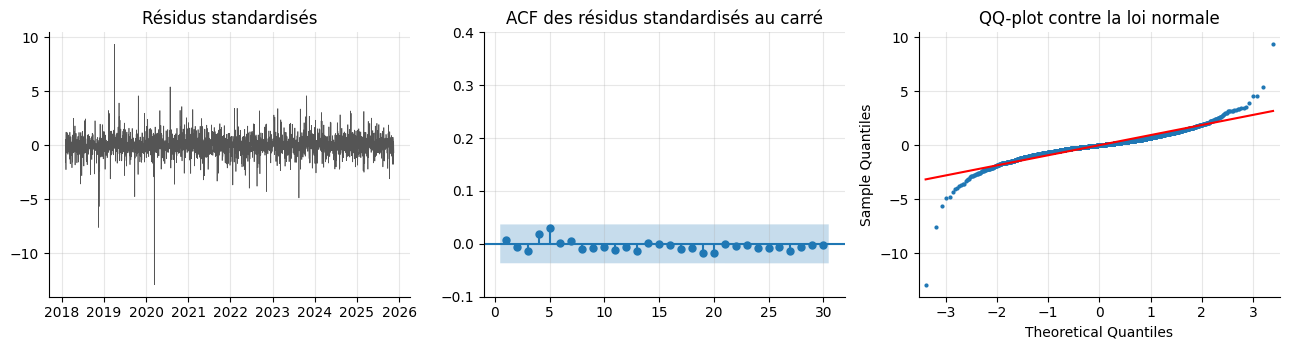

série,"Résidus standardisés — EGARCH(1,1) Student"
Ljung-Box(10) p,0.1269
Ljung-Box(20) p,0.3509
Jarque-Bera p,0.0000
skewness,-0.8027
kurtosis,23.4736
ARCH-LM(10) p,0.8706
Ljung-Box résidus²(10) p,0.8688


In [29]:
# Affiche les paramètres du modèle retenu et en déduit persistance et demi-vie : ce sont les grandeurs à interpréter.
print(garch_fin.summary().tables[1]); print(garch_fin.summary().tables[2])
if "nu" in garch_fin.params: print(garch_fin.summary().tables[3])
pers = float(tab_garch.loc[NOM_GARCH, "persistance"])
demi_vie_vol = float(np.log(0.5) / np.log(pers)) if 0 < pers < 1 else float("nan")
print(f"\nPersistance = {pers:.4f} → demi-vie d'un choc de volatilité : {demi_vie_vol:.0f} jours")
if "nu" in garch_fin.params:
    print(f"Degrés de liberté de la loi de Student : {garch_fin.params['nu']:.2f} (plus il est petit, plus les queues sont épaisses ; la loi normale correspond à l'infini)")
if "gamma[1]" in garch_fin.params:
    print("Effet d'asymétrie (gamma) :", verdict(garch_fin.pvalues["gamma[1]"], "pas d'asymétrie"))

# Diagnostique les résidus standardisés : si le GARCH a bien capté la volatilité, l'effet ARCH doit avoir disparu.
z_fin = garch_fin.std_resid.dropna()
diag_garch = diagnostic(z_fin, f"Résidus standardisés — {NOM_GARCH}")
print("\nDiagnostic des résidus standardisés :"); conclure_diagnostic(diag_garch)
avant, apres = diag_arima["ARCH-LM(10) p"], diag_garch["ARCH-LM(10) p"]
print(f"\nARCH-LM(10) : p = {avant:.4f} avant GARCH → p = {apres:.4f} après GARCH.",
      "L'hétéroscédasticité est correctement modélisée." if apres >= ALPHA else "Il reste de l'effet ARCH : un ordre supérieur est à envisager.")
R["garch"] = {"retenu": NOM_GARCH, "parametres": garch_fin.params.to_dict(), "p_values": garch_fin.pvalues.to_dict(),
              "persistance": pers, "demi_vie_jours": demi_vie_vol, "diagnostic": diag_garch,
              "comparaison": tab_garch.to_dict(orient="index")}

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].plot(z_fin, color=C_GRIS, lw=0.5); ax[0].set_title("Résidus standardisés")
plot_acf(z_fin ** 2, lags=30, ax=ax[1], zero=False, title="ACF des résidus standardisés au carré"); ax[1].set_ylim(-0.1, 0.4)
sm.qqplot(z_fin, line="s", ax=ax[2], markersize=2); ax[2].set_title("QQ-plot contre la loi normale")
sauver(fig, "10_diagnostic_garch")
table(pd.DataFrame([diag_garch]).set_index("série").T, "03_diagnostic_garch")

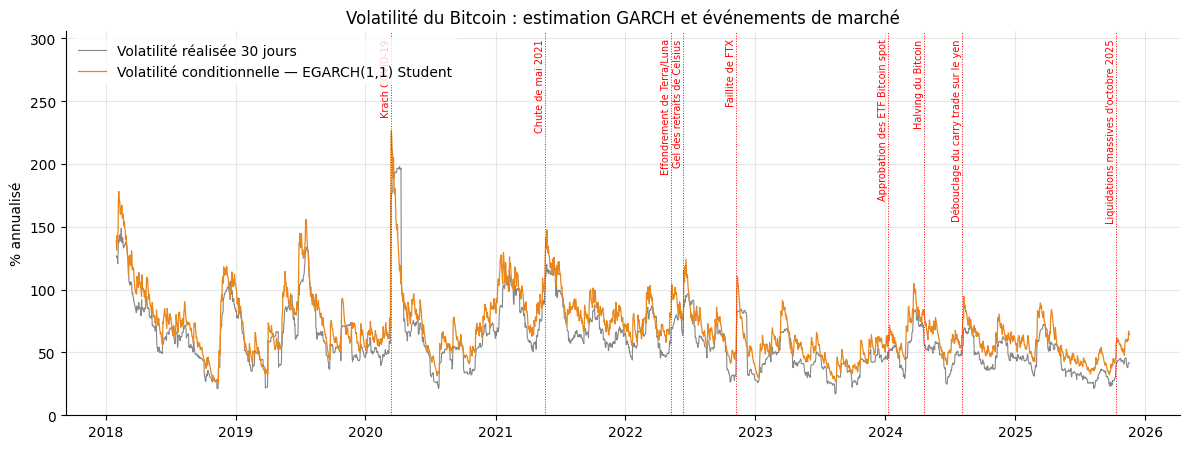

Volatilité conditionnelle médiane : 66 % | maximale : 226 % le 2020-03-14


,date,volatilité max sur 5 jours (%),rapport à la médiane,rendement du jour (%)
événement,,,,
Krach COVID-19,2020-03-12,226.25,3.44,-46.47
Chute de mai 2021 (restrictions en Chine),2021-05-19,140.64,2.14,-14.81
Effondrement de Terra/Luna,2022-05-09,103.74,1.58,-11.71
Gel des retraits de Celsius,2022-06-13,118.70,1.81,-17.41
Faillite de FTX,2022-11-08,110.72,1.69,-10.54
Approbation des ETF Bitcoin spot,2024-01-10,71.48,1.09,1.05
Halving du Bitcoin,2024-04-20,79.52,1.21,1.79
Débouclage du carry trade sur le yen,2024-08-05,94.44,1.44,-7.36
Liquidations massives d'octobre 2025,2025-10-10,61.54,0.94,-7.23


In [30]:
# Trace la volatilité conditionnelle avec les événements connus : relie le modèle à l'histoire du marché, comme le demande la section 3.3.
vol_cond = garch_fin.conditional_volatility * np.sqrt(365)          # déjà en % : on annualise seulement
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(100 * train["vol30_BTC"], color=C_GRIS, lw=0.8, alpha=0.7, label="Volatilité réalisée 30 jours")
ax.plot(vol_cond, color=C_BTC, lw=0.9, label=f"Volatilité conditionnelle — {NOM_GARCH}")
haut = 1.35 * float(vol_cond.max())          # marge au-dessus des courbes pour loger les étiquettes
ax.set_ylim(0, haut)
for date_, nom in EVENEMENTS.items():
    d_ = pd.Timestamp(date_)
    if train.index[0] <= d_ <= train.index[-1]:
        ax.axvline(d_, color="red", lw=0.7, ls=":")
        ax.text(d_, 0.99 * haut, nom.split(" (")[0] + " ", rotation=90, fontsize=7, color="red", va="top", ha="right")
ax.set_ylabel("% annualisé"); ax.set_title("Volatilité du Bitcoin : estimation GARCH et événements de marché"); ax.legend(frameon=True, facecolor="white", edgecolor="none", loc="upper left")
sauver(fig, "11_volatilite_conditionnelle")

# Mesure la volatilité estimée autour de chaque événement : remplace une lecture visuelle par un chiffre.
mediane = float(vol_cond.median())
ev = []
for date_, nom in EVENEMENTS.items():
    d_ = pd.Timestamp(date_)
    if train.index[0] <= d_ <= train.index[-1] - pd.Timedelta(days=5):
        pic = float(vol_cond.loc[d_:d_ + pd.Timedelta(days=5)].max())
        ev.append({"événement": nom, "date": date_, "volatilité max sur 5 jours (%)": pic, "rapport à la médiane": pic / mediane,
                   "rendement du jour (%)": float(100 * df.loc[d_, "r_BTC"])})
tab_ev = pd.DataFrame(ev).set_index("événement")
R["volatilite"] = {"mediane_%": mediane, "max_%": float(vol_cond.max()), "date_max": str(vol_cond.idxmax().date()),
                   "evenements": tab_ev.to_dict(orient="index")}
print(f"Volatilité conditionnelle médiane : {mediane:.0f} % | maximale : {vol_cond.max():.0f} % le {vol_cond.idxmax().date()}")
table(tab_ev, "03_volatilite_evenements", 2)

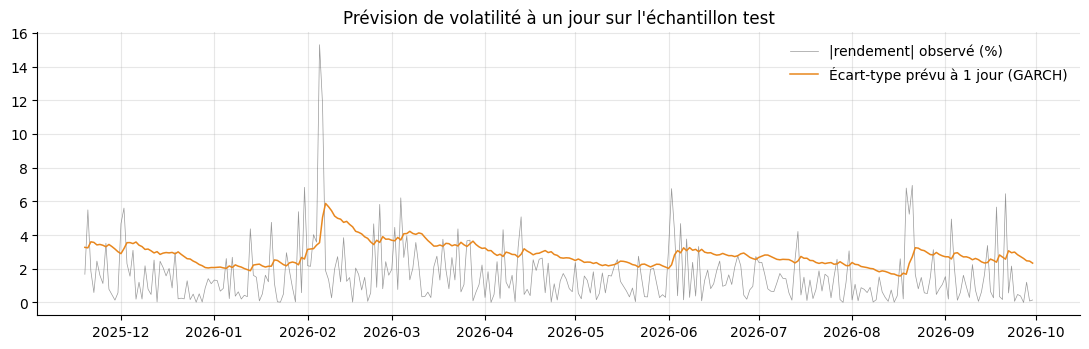

,QLIKE,MSE
"EGARCH(1,1) Student",2.7435,297.7791
Variance historique 30 j,2.8092,296.9754
Variance constante (train),2.9322,323.9945


Meilleure prévision de volatilité selon QLIKE : EGARCH(1,1) Student


In [31]:
# Évalue le GARCH hors échantillon contre deux références simples : un modèle de volatilité doit lui aussi battre sa baseline.
try:
    r_pct = 100 * df["r_BTC"]
    g_oos = arch_model(r_pct, mean="Constant", **SPECS[NOM_GARCH]).fit(last_obs=date_coupe, disp="off")
    # La prévision faite le jour t concerne t+1 : on décale d'un jour pour l'aligner sur la date cible.
    var_garch = g_oos.forecast(horizon=1, start=date_coupe).variance["h.1"].shift(1).dropna()
    cible = (r_pct - g_oos.params["mu"]) ** 2
    var_hist = r_pct.rolling(30).var().shift(1)
    var_const = pd.Series(r_pct_train.var(), index=df.index)
    idx = var_garch.index
    qlike = lambda v: float(np.mean(np.log(v[idx]) + cible[idx] / v[idx]))
    mse_v = lambda v: float(np.mean((cible[idx] - v[idx]) ** 2))
    tab_vol = pd.DataFrame({"QLIKE": {NOM_GARCH: qlike(var_garch), "Variance historique 30 j": qlike(var_hist), "Variance constante (train)": qlike(var_const)},
                            "MSE": {NOM_GARCH: mse_v(var_garch), "Variance historique 30 j": mse_v(var_hist), "Variance constante (train)": mse_v(var_const)}})
    R["garch_hors_echantillon"] = tab_vol.to_dict(orient="index")
    fig, ax = plt.subplots(figsize=(11, 3.6))
    ax.plot(np.sqrt(cible[idx]), color=C_GRIS, lw=0.5, alpha=0.6, label="|rendement| observé (%)")
    ax.plot(np.sqrt(var_garch), color=C_BTC, lw=1.1, label="Écart-type prévu à 1 jour (GARCH)")
    ax.set_title("Prévision de volatilité à un jour sur l'échantillon test"); ax.legend(frameon=False)
    sauver(fig, "12_garch_test")
    display(table(tab_vol, "03_garch_hors_echantillon"))
    print("Meilleure prévision de volatilité selon QLIKE :", tab_vol["QLIKE"].idxmin())
except Exception as e:
    R["garch_hors_echantillon"] = {"erreur": str(e)[:300]}
    print("Évaluation hors échantillon du GARCH non réalisée :", e)

In [32]:
# Importe TensorFlow à part : c'est la seule dépendance lourde, utilisée uniquement dans cette section.
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
R["versions"]["tensorflow"] = tf.__version__
print("TensorFlow", tf.__version__, "| GPU disponible :", len(tf.config.list_physical_devices("GPU")) > 0)

# Construit les entrées et les cibles : la cible Y[t, k] est le rendement du jour t+1+k, donc strictement postérieure à l'entrée.
ENTREES = ["r_BTC", "r_ETH", "vol30_BTC"]
F = df[ENTREES].values.astype("float32")
rB = df["r_BTC"].values.astype("float32")
Y = np.full((N, H), np.nan, dtype="float32")
for k in range(H):
    Y[:N - 1 - k, k] = rB[1 + k:]

def fenetres(Fs, ts, W):
    """Empile, pour chaque origine t, les W dernières lignes connues à la date t."""
    return np.stack([Fs[t - W + 1:t + 1] for t in ts])

def construire(type_cellule, W, unites, dropout):
    """Une seule couche récurrente : l'échantillon est petit et bruité, un réseau profond surapprendrait."""
    cellule = layers.LSTM if type_cellule == "LSTM" else layers.GRU
    modele = keras.Sequential([layers.Input(shape=(W, F.shape[1])), cellule(unites), layers.Dropout(dropout), layers.Dense(H)])
    modele.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return modele

def entrainer(type_cellule, t_fit, t_val, W=30, unites=32, dropout=0.2, epoques=60, patience=8):
    """Normalise sur la partie d'ajustement seulement, entraîne avec arrêt anticipé, renvoie une fonction de prévision."""
    fin = t_fit.max() + 1
    mu, sd = F[:fin].mean(axis=0), F[:fin].std(axis=0)
    sy = rB[1:fin].std()
    Fs = (F - mu) / sd
    keras.utils.set_random_seed(SEED)
    modele = construire(type_cellule, W, unites, dropout)
    t0 = time.time()
    hist = modele.fit(fenetres(Fs, t_fit, W), Y[t_fit] / sy, validation_data=(fenetres(Fs, t_val, W), Y[t_val] / sy),
                      epochs=epoques, batch_size=64, verbose=0,
                      callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)])
    predire = lambda ts: modele.predict(fenetres(Fs, np.asarray(ts), W), verbose=0) * sy
    return modele, hist.history, predire, time.time() - t0

# Origines utilisables pour l'apprentissage : la dernière cible (t + H) doit rester dans le train.
W_MAX = 60
T_APP = np.arange(W_MAX - 1, n_train - H)
n_val = int(0.10 * len(T_APP))
T_FIT, T_VAL = T_APP[:-n_val - H], T_APP[-n_val:]       # intervalle de H jours : aucune cible d'ajustement ne déborde sur la validation
# Perte de la prévision « rendement nul » sur la validation, dans la même unité que la perte du réseau : c'est le niveau à battre.
PERTE_NAIVE = float(np.mean((Y[T_VAL] / rB[1:T_FIT.max() + 1].std()) ** 2))
print(f"Perte de validation de la prévision naïve (rendement nul) : {PERTE_NAIVE:.4f}")
print(f"Exemples d'ajustement : {len(T_FIT)} | de validation : {len(T_VAL)} | dernière cible utilisée : {df.index[T_APP.max() + H].date()} (dans le train)")

TensorFlow 2.21.0 | GPU disponible : False
Perte de validation de la prévision naïve (rendement nul) : 0.3942
Exemples d'ajustement : 2492 | de validation : 277 | dernière cible utilisée : 2025-11-17 (dans le train)


In [33]:
# Compare quelques configurations sur la validation : justifie les hyperparamètres par une mesure plutôt que par une habitude.
CONFIGS = [(10, 32, 0.2), (30, 16, 0.2), (30, 32, 0.2), (30, 32, 0.0), (30, 64, 0.2), (60, 32, 0.2)]
essais = []
for W_, u_, dr_ in CONFIGS:
    m_, h_, _, duree = entrainer("LSTM", T_FIT, T_VAL, W=W_, unites=u_, dropout=dr_, epoques=30, patience=5)
    essais.append({"fenêtre W": W_, "unités": u_, "dropout": dr_, "paramètres": m_.count_params(),
                   "perte validation": min(h_["val_loss"]), "rapport au naïf": min(h_["val_loss"]) / PERTE_NAIVE, "perte ajustement": h_["loss"][int(np.argmin(h_["val_loss"]))],
                   "époque retenue": int(np.argmin(h_["val_loss"])) + 1, "durée_s": duree})
tab_hp = pd.DataFrame(essais)
meilleur = tab_hp.sort_values("perte validation").iloc[0]
W, UNITES, DROPOUT = int(meilleur["fenêtre W"]), int(meilleur["unités"]), float(meilleur["dropout"])
etendue = tab_hp["perte validation"].max() - tab_hp["perte validation"].min()
R["hyperparametres"] = {"perte_naive_validation": PERTE_NAIVE, "W": W, "unites": UNITES, "dropout": DROPOUT, "essais": tab_hp.to_dict(orient="records")}
print(f"Configuration retenue : fenêtre = {W} jours, {UNITES} unités, dropout = {DROPOUT}")
print(f"Écart de perte de validation entre la meilleure et la moins bonne configuration : {etendue:.4f}")
print("Un écart très faible signifie que le choix des hyperparamètres compte peu : le signal à apprendre est lui-même faible.")
table(tab_hp.set_index(["fenêtre W", "unités", "dropout"]), "04_hyperparametres")

Configuration retenue : fenêtre = 60 jours, 32 unités, dropout = 0.2
Écart de perte de validation entre la meilleure et la moins bonne configuration : 0.0032
Un écart très faible signifie que le choix des hyperparamètres compte peu : le signal à apprendre est lui-même faible.


paramètres  perte validation  rapport au naïf  \
fenêtre W unités dropout                                                  
10        32     0.2            4938            0.3942           0.9999   
30        16     0.2            1450            0.3973           1.0080   
          32     0.2            4938            0.3941           0.9998   
                 0.0            4938            0.3951           1.0022   
          64     0.2           18058            0.3959           1.0044   
60        32     0.2            4938            0.3941           0.9998   

                          perte ajustement  époque retenue  durée_s  
fenêtre W unités dropout                                             
10        32     0.2                0.9584               2   3.6780  
30        16     0.2                0.9535              10   7.1841  
          32     0.2                0.9583               2   5.7127  
                 0.0                0.9544               2   4.2880  
          64     0.2                0.9530               4   7.4036  
60        32     0.2                0.9583               2   7.8621

LSTM : 4938 paramètres | 10 époques, meilleure à l'époque 2 | perte validation = 0.3941, soit 0.9998 fois le naïf | 9 s
GRU : 3882 paramètres | 13 époques, meilleure à l'époque 5 | perte validation = 0.3948, soit 1.0017 fois le naïf | 15 s


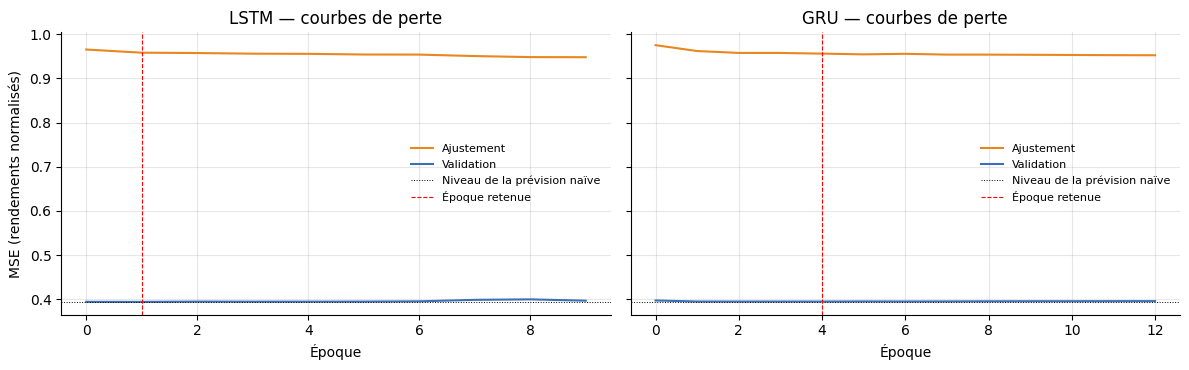

In [34]:
# Entraîne LSTM et GRU avec la même configuration et les mêmes données : seule l'architecture diffère, la comparaison est donc propre.
RESEAUX, HISTORIQUES = {}, {}
for type_cellule in ["LSTM", "GRU"]:
    modele, historique, predire, duree = entrainer(type_cellule, T_FIT, T_VAL, W=W, unites=UNITES, dropout=DROPOUT)
    RESEAUX[type_cellule], HISTORIQUES[type_cellule], TEMPS[type_cellule] = modele, historique, duree
    # Les rendements prévus sont cumulés et ajoutés au dernier log-prix connu : même format de sortie que les autres modèles.
    CHEMINS[type_cellule] = logp_v[ORIGINES][:, None] + np.cumsum(predire(ORIGINES), axis=1)
    ep = int(np.argmin(historique["val_loss"])) + 1
    print(f"{type_cellule} : {modele.count_params()} paramètres | {len(historique['loss'])} époques, meilleure à l'époque {ep} "
          f"| perte validation = {min(historique['val_loss']):.4f}, soit {min(historique['val_loss']) / PERTE_NAIVE:.4f} fois le naïf | {duree:.0f} s")

# Trace les courbes de perte : c'est le document exigé par le sujet pour juger du surapprentissage.
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for k, type_cellule in enumerate(["LSTM", "GRU"]):
    h_ = HISTORIQUES[type_cellule]
    ax[k].plot(h_["loss"], color=C_BTC, label="Ajustement"); ax[k].plot(h_["val_loss"], color=C_ETH, label="Validation")
    ax[k].axhline(PERTE_NAIVE, color="black", lw=0.7, ls=":", label="Niveau de la prévision naïve")
    ax[k].axvline(int(np.argmin(h_["val_loss"])), color="red", lw=0.8, ls="--", label="Époque retenue")
    ax[k].set_title(f"{type_cellule} — courbes de perte"); ax[k].set_xlabel("Époque"); ax[k].legend(frameon=False, fontsize=8)
ax[0].set_ylabel("MSE (rendements normalisés)")
sauver(fig, "13_courbes_perte")
R["reseaux"] = {t_: {"parametres": int(RESEAUX[t_].count_params()), "epoques": len(HISTORIQUES[t_]["loss"]),
                     "meilleure_epoque": int(np.argmin(HISTORIQUES[t_]["val_loss"])) + 1,
                     "perte_validation": float(min(HISTORIQUES[t_]["val_loss"])),
                     "rapport_au_naif": float(min(HISTORIQUES[t_]["val_loss"]) / PERTE_NAIVE),
                     "perte_ajustement_finale": float(HISTORIQUES[t_]["loss"][-1])} for t_ in RESEAUX}

In [35]:
# Validation walk-forward à 4 plis : mesure si la performance des réseaux est stable dans le temps ou due à une période particulière.
decoupe = TimeSeriesSplit(n_splits=4, gap=H)
vc = []
for pli, (i_app, i_test) in enumerate(decoupe.split(T_APP), start=1):
    t_app, t_test = T_APP[i_app], T_APP[i_test]
    nv = int(0.15 * len(t_app))
    t_fit, t_val = t_app[:-nv - H], t_app[-nv:]
    reel = Y[t_test, 0]
    rmse_naif = float(np.sqrt(np.mean(reel ** 2)))                     # la prévision naïve du rendement est zéro
    for type_cellule in ["LSTM", "GRU"]:
        _, _, predire, _ = entrainer(type_cellule, t_fit, t_val, W=W, unites=UNITES, dropout=DROPOUT, epoques=30, patience=5)
        rmse = float(np.sqrt(np.mean((predire(t_test)[:, 0] - reel) ** 2)))
        vc.append({"pli": pli, "modèle": type_cellule, "test du": df.index[t_test[0]].date(), "au": df.index[t_test[-1]].date(),
                   "exemples ajustement": len(t_fit), "RMSE rendement (%)": 100 * rmse, "RMSE naïf (%)": 100 * rmse_naif,
                   "rapport au naïf": rmse / rmse_naif})
tab_vc = pd.DataFrame(vc)
resume_vc = tab_vc.groupby("modèle")["rapport au naïf"].agg(["mean", "std", "min", "max"])
R["validation_croisee"] = {"plis": tab_vc.astype(str).to_dict(orient="records"), "resume": resume_vc.to_dict(orient="index")}
print("Rapport RMSE réseau / RMSE naïf sur les 4 plis (inférieur à 1 = le réseau fait mieux que le naïf) :")
display(resume_vc.round(4))
table(tab_vc.set_index(["pli", "modèle"]), "04_validation_croisee")

Rapport RMSE réseau / RMSE naïf sur les 4 plis (inférieur à 1 = le réseau fait mieux que le naïf) :


,mean,std,min,max
modèle,,,,
GRU,0.9971,0.0019,0.9947,0.9988
LSTM,1.0000,0.0039,0.9963,1.0055


test du          au  exemples ajustement  RMSE rendement (%)  \
pli modèle                                                                    
1   LSTM    2019-10-11  2021-04-17                  457              3.9859   
    GRU     2019-10-11  2021-04-17                  457              3.9865   
2   LSTM    2021-04-18  2022-10-24                  929              3.7189   
    GRU     2021-04-18  2022-10-24                  929              3.7173   
3   LSTM    2022-10-25  2024-05-01                 1401              2.6041   
    GRU     2022-10-25  2024-05-01                 1401              2.5759   
4   LSTM    2024-05-02  2025-11-07                 1872              2.3888   
    GRU     2024-05-02  2025-11-07                 1872              2.3879   

            RMSE naïf (%)  rapport au naïf  
pli modèle                                  
1   LSTM           4.0008           0.9963  
    GRU            4.0008           0.9964  
2   LSTM           3.7216           0.9993  
    GRU            3.7216           0.9988  
3   LSTM           2.5897           1.0055  
    GRU            2.5897           0.9947  
4   LSTM           2.3914           0.9989  
    GRU            2.3914           0.9985

In [36]:
# Récupère les erreurs à un pas de l'ARIMA sur toute la série, paramètres figés : ce sont les entrées et les cibles du LSTM hybride.
e_arima = np.asarray(arima_fin.apply(logp).resid, dtype="float32")
e_arima[:max(d, 1)] = 0.0                                  # les premiers résidus sont un artefact d'initialisation
s_e = e_arima[1:n_train].std()
E = (e_arima / s_e)[:, None]

# Fenêtres de résidus → résidu du lendemain ; la dernière cible d'entraînement reste dans le train.
t_h = np.arange(W - 1, n_train - 1)
nvh = int(0.10 * len(t_h))
t_hfit, t_hval = t_h[:-nvh - 1], t_h[-nvh:]
Xh = lambda ts: np.stack([E[t - W + 1:t + 1] for t in ts])
yh = lambda ts: E[np.asarray(ts) + 1, 0]

keras.utils.set_random_seed(SEED)
hybride = keras.Sequential([layers.Input(shape=(W, 1)), layers.LSTM(16), layers.Dropout(0.2), layers.Dense(1)])
hybride.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
t0 = time.time()
hist_h = hybride.fit(Xh(t_hfit), yh(t_hfit), validation_data=(Xh(t_hval), yh(t_hval)), epochs=60, batch_size=64, verbose=0,
                     callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)])
TEMPS["Hybride ARIMA+LSTM"] = duree_arima + time.time() - t0

# Ajoute la correction prévue par le LSTM à la prévision ARIMA à un jour ; les horizons supérieurs ne sont pas évalués.
correction = hybride.predict(Xh(ORIGINES), verbose=0)[:, 0] * s_e
ch = np.full((len(ORIGINES), H), np.nan)
ch[:, 0] = CHEMINS["ARIMA"][:, 0] + correction
CHEMINS["Hybride ARIMA+LSTM"] = ch
naif_h = float(np.mean(yh(t_hval) ** 2))                  # perte de la prévision « résidu nul » sur la même validation
R["hybride"] = {"parametres": int(hybride.count_params()), "perte_validation": float(min(hist_h.history["val_loss"])),
                "rapport_au_naif": float(min(hist_h.history["val_loss"]) / naif_h),
                "meilleure_epoque": int(np.argmin(hist_h.history["val_loss"])) + 1,
                "correction_moyenne_abs": float(np.mean(np.abs(correction))), "ecart_type_residus": float(s_e)}
print(f"Perte de validation du LSTM sur résidus : {min(hist_h.history['val_loss']):.4f}, soit {min(hist_h.history['val_loss']) / naif_h:.4f} fois celle de la prévision « résidu nul » (1,00 = aucun pouvoir prédictif)")
print(f"Taille moyenne de la correction : {np.mean(np.abs(correction)):.5f} en log, pour un écart-type des résidus de {s_e:.5f}")

Perte de validation du LSTM sur résidus : 0.4272, soit 0.9997 fois celle de la prévision « résidu nul » (1,00 = aucun pouvoir prédictif)
Taille moyenne de la correction : 0.00093 en log, pour un écart-type des résidus de 0.03385


In [37]:
# Rassemble toutes les métriques dans un tableau unique : mêmes dates cibles, mêmes unités, mêmes horizons pour tous les modèles.
lignes = []
for nom, chemins in CHEMINS.items():
    for h in HORIZONS:
        prev, reel = extraire(chemins, h)
        if len(prev) == 0:
            continue
        m_ = metriques(prev, reel)
        m_.update({"modèle": nom, "horizon": h, "n": len(prev)})
        lignes.append(m_)
tab_m = pd.DataFrame(lignes)
ref = tab_m[tab_m["modèle"] == "Naïf"].set_index("horizon")["RMSE"]
tab_m["RMSE relatif au naïf"] = tab_m["RMSE"] / tab_m["horizon"].map(ref)
tab_m = tab_m.set_index(["horizon", "modèle"]).sort_index(level=0, sort_remaining=False)[["n", "MSE", "RMSE", "MAE", "MAPE_%", "RMSE relatif au naïf"]]
tab_m.to_csv("resultats/tables/06_metriques.csv")
R["metriques"] = {f"h={h}": tab_m.loc[h].to_dict(orient="index") for h in HORIZONS}
tab_m.round({"MSE": 0, "RMSE": 1, "MAE": 1, "MAPE_%": 3, "RMSE relatif au naïf": 4})

n         MSE    RMSE     MAE  MAPE_%  \
horizon modèle                                                        
1       Naïf                317   3063521.0  1750.3  1196.2   1.605   
        ARIMA               317   3072371.0  1752.8  1199.2   1.608   
        VAR                 317   3078056.0  1754.4  1212.5   1.623   
        LSTM                317   3070559.0  1752.3  1201.1   1.613   
        GRU                 317   3067527.0  1751.4  1201.0   1.611   
        Hybride ARIMA+LSTM  317   3087477.0  1757.1  1205.4   1.617   
5       Naïf                317  15381181.0  3921.9  2779.9   3.701   
        ARIMA               317  15360771.0  3919.3  2778.1   3.698   
        VAR                 317  15491607.0  3935.9  2809.9   3.746   
        LSTM                317  15530324.0  3940.9  2802.4   3.734   
        GRU                 317  15421694.0  3927.0  2805.8   3.740   
10      Naïf                317  35841897.0  5986.8  4242.1   5.695   
        ARIMA               317  35816870.0  5984.7  4240.0   5.692   
        VAR                 317  37061126.0  6087.8  4296.6   5.786   
        LSTM                317  36963690.0  6079.8  4281.5   5.761   
        GRU                 317  36643258.0  6053.4  4270.9   5.752   

                            RMSE relatif au naïf  
horizon modèle                                    
1       Naïf                              1.0000  
        ARIMA                             1.0014  
        VAR                               1.0024  
        LSTM                              1.0011  
        GRU                               1.0007  
        Hybride ARIMA+LSTM                1.0039  
5       Naïf                              1.0000  
        ARIMA                             0.9993  
        VAR                               1.0036  
        LSTM                              1.0048  
        GRU                               1.0013  
10      Naïf                              1.0000  
        ARIMA                             0.9997  
        VAR                               1.0169  
        LSTM                              1.0155  
        GRU                               1.0111

In [38]:
# Implémente Diebold-Mariano avec correction HLN : aucun package Python standard ne le fournit, et la formule tient en quelques lignes.
def diebold_mariano(e1, e2, h=1):
    d_ = np.asarray(e1) ** 2 - np.asarray(e2) ** 2
    n = len(d_)
    if n < 10 or np.allclose(d_, 0):
        return np.nan, np.nan                    # prévisions identiques : le test n'est pas défini
    m = d_.mean()
    gam = [np.sum((d_[k:] - m) * (d_[:n - k] - m)) / n for k in range(h)]
    variance = (gam[0] + 2 * sum(gam[1:])) / n
    if variance <= 0:
        return np.nan, np.nan
    stat = m / np.sqrt(variance) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return float(stat), float(2 * stats.t.sf(abs(stat), df=n - 1))

def erreurs(nom, h):
    prev, reel = extraire(CHEMINS[nom], h)
    return reel - prev

# Compare chaque modèle au naïf à chaque horizon : c'est la question « ce modèle apporte-t-il quelque chose ? ».
dm = []
for nom in CHEMINS:
    if nom == "Naïf": continue
    for h in HORIZONS:
        e1, e2 = erreurs(nom, h), erreurs("Naïf", h)
        if len(e1) == 0: continue
        commun = e1.index.intersection(e2.index)
        stat, p = diebold_mariano(e1[commun].values, e2[commun].values, h)
        dm.append({"modèle": nom, "horizon": h, "statistique DM": stat, "p_value": p,
                   "conclusion": "non défini" if np.isnan(p) else ("meilleur que le naïf" if (p < ALPHA and stat < 0) else
                                  "moins bon que le naïf" if (p < ALPHA and stat > 0) else "pas de différence significative")})
tab_dm = pd.DataFrame(dm).set_index(["horizon", "modèle"]).sort_index(level=0, sort_remaining=False)
R["diebold_mariano_vs_naif"] = {f"h={h}": tab_dm.loc[h].to_dict(orient="index") for h in HORIZONS if h in tab_dm.index.get_level_values(0)}
table(tab_dm, "06_diebold_mariano_vs_naif")

statistique DM  p_value  \
horizon modèle                                        
1       ARIMA                       0.3149   0.7531   
        VAR                         0.3288   0.7426   
        LSTM                        0.2129   0.8315   
        GRU                         0.1474   0.8829   
        Hybride ARIMA+LSTM          0.4914   0.6235   
5       ARIMA                      -0.5355   0.5927   
        VAR                         0.3704   0.7113   
        LSTM                        0.8131   0.4168   
        GRU                         0.1597   0.8732   
10      ARIMA                      -0.5186   0.6044   
        VAR                         0.9618   0.3369   
        LSTM                        0.9133   0.3618   
        GRU                         0.7575   0.4493   

                                                 conclusion  
horizon modèle                                               
1       ARIMA               pas de différence significative  
        VAR                 pas de différence significative  
        LSTM                pas de différence significative  
        GRU                 pas de différence significative  
        Hybride ARIMA+LSTM  pas de différence significative  
5       ARIMA               pas de différence significative  
        VAR                 pas de différence significative  
        LSTM                pas de différence significative  
        GRU                 pas de différence significative  
10      ARIMA               pas de différence significative  
        VAR                 pas de différence significative  
        LSTM                pas de différence significative  
        GRU                 pas de différence significative

In [39]:
# Matrice des p-values entre toutes les paires à h = 1 : permet de dire si le classement entre modèles est statistiquement fondé.
noms = list(CHEMINS)
mat = pd.DataFrame(np.nan, index=noms, columns=noms)
for a_ in noms:
    for b_ in noms:
        if a_ != b_:
            mat.loc[a_, b_] = diebold_mariano(erreurs(a_, 1).values, erreurs(b_, 1).values, 1)[1]
R["diebold_mariano_paires_h1"] = mat.to_dict()
print("p-values du test de Diebold-Mariano entre paires de modèles, horizon 1 jour (p < 0,05 : précisions différentes)")
table(mat, "06_diebold_mariano_paires_h1")

p-values du test de Diebold-Mariano entre paires de modèles, horizon 1 jour (p < 0,05 : précisions différentes)


,Naïf,ARIMA,VAR,LSTM,GRU,Hybride ARIMA+LSTM
Naïf,NaN,0.7531,0.7426,0.8315,0.8829,0.6235
ARIMA,0.7531,NaN,0.8517,0.9526,0.8189,0.5759
VAR,0.7426,0.8517,NaN,0.8709,0.7315,0.8009
LSTM,0.8315,0.9526,0.8709,NaN,0.9090,0.6223
GRU,0.8829,0.8189,0.7315,0.9090,NaN,0.4649
Hybride ARIMA+LSTM,0.6235,0.5759,0.8009,0.6223,0.4649,NaN


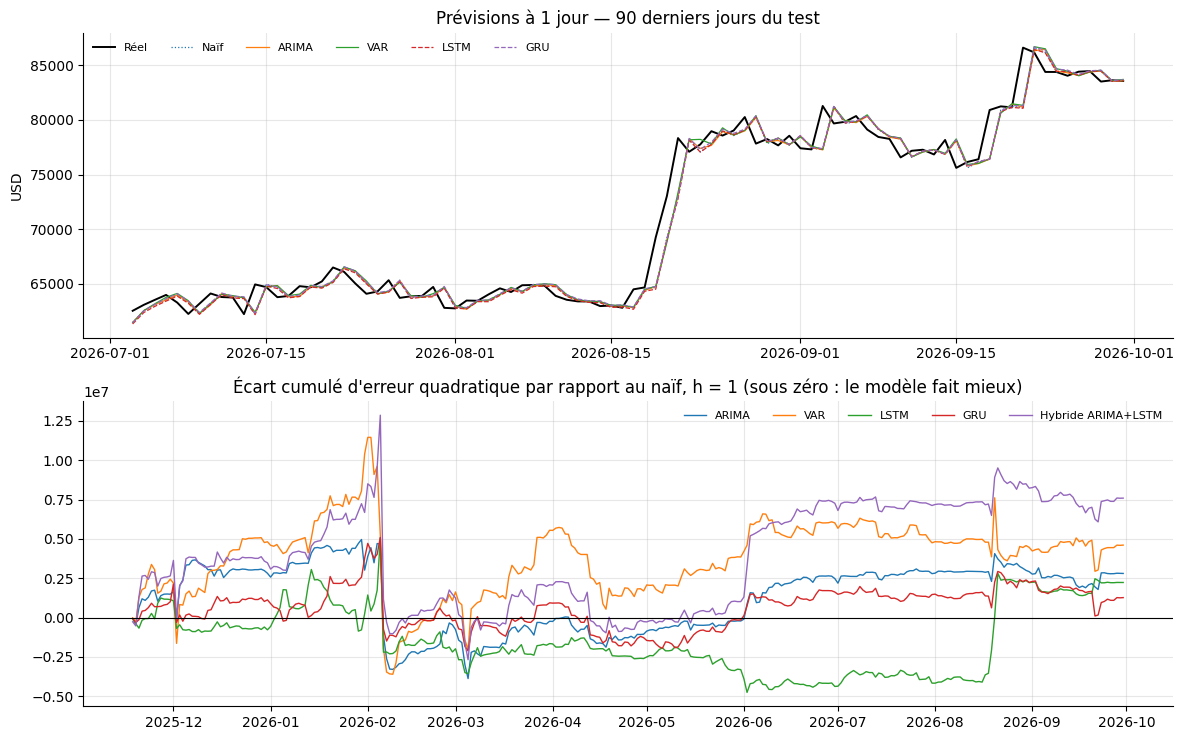

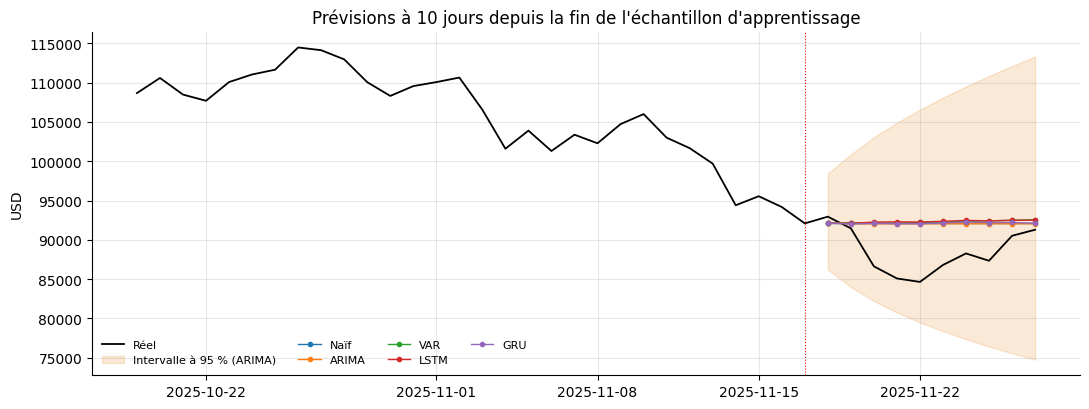

Couverture empirique de l'intervalle à 95 % de l'ARIMA à 1 jour sur le test : 98.4% (attendu : 95 %)


In [40]:
# Trace les prévisions à 1 jour sur les 90 derniers jours : sur tout le test, les courbes seraient indiscernables.
fig, ax = plt.subplots(2, 1, figsize=(12, 7.5))
reel = prix.iloc[n_train:]
ax[0].plot(reel.iloc[-90:], color="black", lw=1.4, label="Réel")
for nom, style in [("Naïf", ":"), ("ARIMA", "-"), ("VAR", "-"), ("LSTM", "--"), ("GRU", "--")]:
    if nom in CHEMINS:
        ax[0].plot(extraire(CHEMINS[nom], 1)[0].iloc[-90:], lw=0.9, ls=style, label=nom)
ax[0].set_title("Prévisions à 1 jour — 90 derniers jours du test"); ax[0].set_ylabel("USD"); ax[0].legend(frameon=False, ncol=6, fontsize=8)

# Trace l'erreur cumulée relative au naïf : montre à quelles périodes un modèle gagne ou perd du terrain.
for nom in CHEMINS:
    if nom == "Naïf": continue
    e1, e2 = erreurs(nom, 1), erreurs("Naïf", 1)
    ax[1].plot((e1 ** 2 - e2 ** 2).cumsum(), lw=1, label=nom)
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_title("Écart cumulé d'erreur quadratique par rapport au naïf, h = 1 (sous zéro : le modèle fait mieux)")
ax[1].legend(frameon=False, ncol=6, fontsize=8)
sauver(fig, "14_previsions_h1")

# Prévision à 10 jours depuis la fin du train avec l'intervalle à 95 % de l'ARIMA : illustre l'incertitude qui croît avec l'horizon.
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(prix.iloc[n_train - 30:n_train + H], color="black", lw=1.3, label="Réel")
dates_f = df.index[n_train:n_train + H]
i0 = int(np.where(ORIGINES == n_train - 1)[0][0])
ax.fill_between(dates_f, ic_arima["borne_basse_95"], ic_arima["borne_haute_95"], color=C_BTC, alpha=0.18, label="Intervalle à 95 % (ARIMA)")
for nom in ["Naïf", "ARIMA", "VAR", "VECM", "LSTM", "GRU"]:
    if nom in CHEMINS:
        ax.plot(dates_f, np.exp(CHEMINS[nom][i0]), marker="o", ms=3, lw=1, label=nom)
ax.axvline(df.index[n_train - 1], color="red", lw=0.8, ls=":")
ax.set_title("Prévisions à 10 jours depuis la fin de l'échantillon d'apprentissage"); ax.set_ylabel("USD"); ax.legend(frameon=False, ncol=4, fontsize=8)
sauver(fig, "15_prevision_10_jours")

# Taux de couverture de l'intervalle à 95 % sur tout le test : vérifie si l'incertitude annoncée par l'ARIMA est réaliste.
se1 = float(arima_fin.get_forecast(1).se_mean.iloc[0])
p1, r1 = extraire(CHEMINS["ARIMA"], 1)
couverture = float(np.mean(np.abs(np.log(r1) - np.log(p1)) <= stats.norm.ppf(1 - ALPHA / 2) * se1))
R["couverture_ic95_arima_h1"] = couverture
print(f"Couverture empirique de l'intervalle à 95 % de l'ARIMA à 1 jour sur le test : {couverture:.1%} (attendu : 95 %)")

In [41]:
# Construit le tableau de synthèse demandé en 8.2 : la performance seule ne suffit pas à choisir un modèle pour un usage réel.
def rmse_rel(nom, h):
    try: return float(tab_m.loc[(h, nom), "RMSE relatif au naïf"])
    except KeyError: return np.nan
def p_dm(nom):
    try: return float(tab_dm.loc[(1, nom), "p_value"])
    except KeyError: return np.nan

NB_PARAM = {"Naïf": 0, "ARIMA": len(arima_fin.params), "VAR": int(var_fin.params.size),
            "LSTM": int(RESEAUX["LSTM"].count_params()), "GRU": int(RESEAUX["GRU"].count_params()),
            "Hybride ARIMA+LSTM": len(arima_fin.params) + int(hybride.count_params())}
INTERPRETABILITE = {
    "Naïf": "Totale : aucune hypothèse à expliquer",
    "ARIMA": "Élevée : quelques coefficients avec tests de significativité",
    "VAR": "Élevée : coefficients, causalité de Granger, réponses impulsionnelles",
    "VECM": "Élevée : relation de long terme et vitesse d'ajustement",
    "LSTM": "Faible : boîte noire, pas de coefficient lisible",
    "GRU": "Faible : boîte noire, pas de coefficient lisible",
    "Hybride ARIMA+LSTM": "Moyenne : partie ARIMA lisible, correction opaque",
}
if "VECM" in CHEMINS:
    NB_PARAM["VECM"] = int(vecm.var_rep.size + vecm.alpha.size)
synthese = pd.DataFrame([{"modèle": nom, "paramètres": NB_PARAM.get(nom, np.nan), "temps d'ajustement (s)": TEMPS.get(nom, np.nan),
                          "RMSE relatif h=1": rmse_rel(nom, 1), "RMSE relatif h=5": rmse_rel(nom, 5), "RMSE relatif h=10": rmse_rel(nom, 10),
                          "DM vs naïf (p, h=1)": p_dm(nom), "intervalles de prévision": "oui" if nom in ["ARIMA", "VAR", "VECM"] else "non",
                          "interprétabilité": INTERPRETABILITE.get(nom, "")} for nom in CHEMINS]).set_index("modèle")
R["synthese"] = synthese.to_dict(orient="index")

# Formule la conclusion à partir des chiffres : évite de déclarer un vainqueur que le test statistique ne confirme pas.
h1 = tab_m.loc[1]
gagnant = h1["RMSE"].idxmin()
print(f"RMSE le plus faible à 1 jour : {gagnant} ({h1.loc[gagnant, 'RMSE']:,.1f} USD, soit {h1.loc[gagnant, 'RMSE relatif au naïf']:.4f} fois le naïf)")
significatifs = tab_dm[(tab_dm["p_value"] < ALPHA) & (tab_dm["statistique DM"] < 0)]
if len(significatifs) == 0:
    print("Aucun modèle ne bat la prévision naïve de façon statistiquement significative, à aucun horizon.")
    print("Conclusion honnête : à cet horizon, le prix du Bitcoin se comporte comme une marche aléatoire.")
else:
    print("Modèles significativement meilleurs que le naïf au seuil de 5 % :"); print(significatifs[["statistique DM", "p_value"]].round(4))
# Corrige pour les comparaisons multiples : avec autant de tests à 5 %, un « succès » isolé peut être dû au seul hasard.
n_tests = int(tab_dm["p_value"].notna().sum())
seuil_bonf = ALPHA / max(n_tests, 1)
robustes = significatifs[significatifs["p_value"] < seuil_bonf]
print(f"\n{n_tests} tests ont été réalisés : on attend environ {ALPHA * n_tests:.1f} faux positif(s) par hasard au seuil de 5 %.")
print(f"Seuil corrigé de Bonferroni : {seuil_bonf:.4f} → {len(robustes)} résultat(s) reste(nt) significatif(s) après correction.")
R["conclusion"] = {"rmse_min_h1": gagnant, "nb_modeles_battant_naif": int(len(significatifs)), "nb_tests": n_tests,
                   "seuil_bonferroni": seuil_bonf, "nb_significatifs_apres_bonferroni": int(len(robustes))}
table(synthese, "06_synthese_modeles")

RMSE le plus faible à 1 jour : Naïf (1,750.3 USD, soit 1.0000 fois le naïf)
Aucun modèle ne bat la prévision naïve de façon statistiquement significative, à aucun horizon.
Conclusion honnête : à cet horizon, le prix du Bitcoin se comporte comme une marche aléatoire.

13 tests ont été réalisés : on attend environ 0.7 faux positif(s) par hasard au seuil de 5 %.
Seuil corrigé de Bonferroni : 0.0038 → 0 résultat(s) reste(nt) significatif(s) après correction.


,paramètres,temps d'ajustement (s),RMSE relatif h=1,RMSE relatif h=5,RMSE relatif h=10,"DM vs naïf (p, h=1)",intervalles de prévision,interprétabilité
modèle,,,,,,,,
Naïf,0,0.0000,1.0000,1.0000,1.0000,NaN,non,Totale : aucune hypothèse à expliquer
ARIMA,3,0.2487,1.0014,0.9993,0.9997,0.7531,oui,Élevée : quelques coefficients avec tests de s...
VAR,18,0.0106,1.0024,1.0036,1.0169,0.7426,oui,"Élevée : coefficients, causalité de Granger, r..."
LSTM,4938,9.3496,1.0011,1.0048,1.0155,0.8315,non,"Faible : boîte noire, pas de coefficient lisible"
GRU,3882,14.9521,1.0007,1.0013,1.0111,0.8829,non,"Faible : boîte noire, pas de coefficient lisible"
Hybride ARIMA+LSTM,1172,6.6443,1.0039,NaN,NaN,0.6235,non,"Moyenne : partie ARIMA lisible, correction opaque"


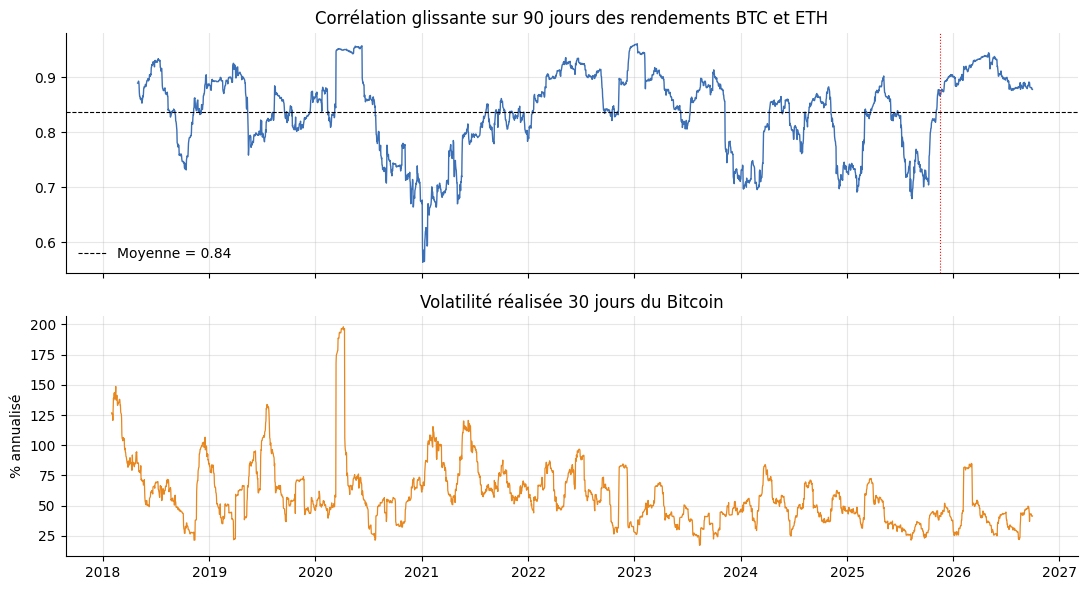

Corrélation glissante : de 0.56 (2021-01-04) à 0.96 (2023-01-11), moyenne 0.84
Moyenne sur le train : 0.83 | sur le test : 0.90
Lien avec la volatilité (Spearman) : -0.01 — p = 0.6668 >= 0.05 : on ne rejette pas H0 (corrélation et volatilité indépendantes)


In [42]:
# Calcule la corrélation sur fenêtre glissante : une corrélation unique masque les changements de régime entre les deux actifs.
corr_gl = df["r_BTC"].rolling(90).corr(df["r_ETH"]).dropna()
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(corr_gl, color=C_ETH, lw=1)
ax[0].axhline(corr_gl.mean(), color="black", lw=0.8, ls="--", label=f"Moyenne = {corr_gl.mean():.2f}")
ax[0].axvline(date_coupe, color="red", lw=0.8, ls=":")
ax[0].set_title("Corrélation glissante sur 90 jours des rendements BTC et ETH"); ax[0].legend(frameon=False)
ax[1].plot(100 * df["vol30_BTC"], color=C_BTC, lw=0.9); ax[1].set_ylabel("% annualisé"); ax[1].set_title("Volatilité réalisée 30 jours du Bitcoin")
sauver(fig, "16_correlation_glissante")

# Mesure le lien entre corrélation et volatilité par une corrélation de rang : robuste aux valeurs extrêmes de volatilité.
lien, p_lien = stats.spearmanr(corr_gl, df["vol30_BTC"].reindex(corr_gl.index))
R["correlation_dynamique"] = {"moyenne": float(corr_gl.mean()), "min": float(corr_gl.min()), "date_min": str(corr_gl.idxmin().date()),
                              "max": float(corr_gl.max()), "date_max": str(corr_gl.idxmax().date()),
                              "moyenne_train": float(corr_gl[:train.index[-1]].mean()), "moyenne_test": float(corr_gl[date_coupe:].mean()),
                              "spearman_avec_volatilite": float(lien), "spearman_p": float(p_lien)}
print(f"Corrélation glissante : de {corr_gl.min():.2f} ({corr_gl.idxmin().date()}) à {corr_gl.max():.2f} ({corr_gl.idxmax().date()}), moyenne {corr_gl.mean():.2f}")
print(f"Moyenne sur le train : {corr_gl[:train.index[-1]].mean():.2f} | sur le test : {corr_gl[date_coupe:].mean():.2f}")
print(f"Lien avec la volatilité (Spearman) : {lien:.2f} —", verdict(p_lien, "corrélation et volatilité indépendantes"))

In [43]:
# Génère les prompts à partir des résultats réels : le LLM raisonne sur les vrais chiffres, et le prompt est documenté mot pour mot.
def f(x, n=4):
    return "non disponible" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.{n}f}"

s = R["stationnarite"]; dB = R["descriptif"]["r_BTC"]; dE = R["descriptif"]["r_ETH"]
prompt1 = f"""Tu es un économètre spécialiste des séries temporelles financières.
Voici les statistiques descriptives de deux séries journalières ({R['decoupage']['n_train']} observations, du {R['donnees']['debut']} au {R['decoupage']['train_fin']}) : le Bitcoin (BTC-USD) et l'Ethereum (ETH-USD).

Rendements logarithmiques journaliers du Bitcoin : moyenne = {f(dB['moyenne'], 5)}, écart-type = {f(dB['ecart_type'], 5)}, minimum = {f(dB['min'])}, maximum = {f(dB['max'])}, skewness = {f(dB['skewness'], 3)}, kurtosis en excès = {f(dB['kurtosis_exces'], 2)}.
Rendements logarithmiques journaliers de l'Ethereum : moyenne = {f(dE['moyenne'], 5)}, écart-type = {f(dE['ecart_type'], 5)}, skewness = {f(dE['skewness'], 3)}, kurtosis en excès = {f(dE['kurtosis_exces'], 2)}.
Corrélation entre les deux rendements : {f(R['corr_rendements'], 3)}.

Tests de stationnarité :
- log-prix BTC : ADF p = {f(s['log-prix BTC']['ADF p'])}, KPSS p = {f(s['log-prix BTC']['KPSS p'])}
- rendements BTC : ADF p = {f(s['rendement BTC (différence 1)']['ADF p'])}, KPSS p = {f(s['rendement BTC (différence 1)']['KPSS p'])}
- log-prix ETH : ADF p = {f(s['log-prix ETH']['ADF p'])}, KPSS p = {f(s['log-prix ETH']['KPSS p'])}
- rendements ETH : ADF p = {f(s['rendement ETH (différence 1)']['ADF p'])}, KPSS p = {f(s['rendement ETH (différence 1)']['KPSS p'])}
(La p-value du KPSS est bornée entre 0,01 et 0,10 par le logiciel.)

Autocorrélation des rendements BTC au retard 1 : {f(R['acf_pacf']['ACF rendements']['valeur_retard_1'])}. Nombre de retards significatifs parmi les 20 premiers : {R['acf_pacf']['ACF rendements']['nb_significatifs_sur_20']} pour les rendements, {R['acf_pacf']['ACF rendements²']['nb_significatifs_sur_20']} pour les rendements au carré.
Force de la saisonnalité hebdomadaire (décomposition STL) : {f(R['stl']['force_saisonnalite'], 3)}.

À partir de ces seules informations :
1. Propose les hypothèses de modèles à tester (famille de modèle, ordres plausibles, transformations), en justifiant chaque hypothèse par une statistique précise ci-dessus.
2. Indique pour chaque hypothèse le test statistique qui permettrait de la valider ou de la rejeter.
3. Signale explicitement ce que ces statistiques ne permettent PAS de conclure.
N'invente aucun chiffre qui ne figure pas ci-dessus."""

mh1 = R["metriques"]["h=1"]; mh10 = R["metriques"]["h=10"]
lignes_m = "\n".join(f"- {nom} : RMSE = {v['RMSE']:,.0f} USD, MAPE = {v['MAPE_%']:.2f} %, RMSE relatif au naïf = {v['RMSE relatif au naïf']:.4f}" for nom, v in mh1.items())
lignes_dm = "\n".join(f"- {nom} contre naïf : statistique = {f(v['statistique DM'], 2)}, p = {f(v['p_value'])}" for nom, v in R["diebold_mariano_vs_naif"]["h=1"].items())
g = R["granger"]; c = R["cointegration"]; ga = R["garch"]
prompt2 = f"""Voici les résultats d'une étude de prévision du prix du Bitcoin, évaluée sur {R['decoupage']['n_test']} jours ({R['decoupage']['test_debut']} au {R['decoupage']['test_fin']}).

Erreurs de prévision à 1 jour :
{lignes_m}

Test de Diebold-Mariano (hypothèse nulle : même précision que la prévision naïve) :
{lignes_dm}

Modèle ARIMA retenu : {R['arima']['retenu']} {R['arima']['tendance']}. Diagnostic des résidus : Ljung-Box p = {f(R['diag_arima']['Ljung-Box(10) p'])}, Jarque-Bera p = {f(R['diag_arima']['Jarque-Bera p'])}, kurtosis = {f(R['diag_arima']['kurtosis'], 1)}, ARCH-LM p = {f(R['diag_arima']['ARCH-LM(10) p'])}.
Causalité de Granger (VAR d'ordre {R['var']['p_retenu']} sur les rendements) : « ETH ne cause pas BTC » p = {f(g['ETH ne cause pas BTC (Granger)']['p_value'])} ; « BTC ne cause pas ETH » p = {f(g['BTC ne cause pas ETH (Granger)']['p_value'])}.
Cointégration des log-prix : test de Johansen, statistique de la trace pour r = 0 : {f(c['trace'][0], 2)} (valeur critique à 5 % : {f(c['critique_5'][0], 2)}) ; Engle-Granger p = {f(c['EG_BTC_sur_ETH_p'])}.
Volatilité : modèle {ga['retenu']}, persistance = {f(ga['persistance'])}, demi-vie d'un choc = {f(ga['demi_vie_jours'], 0)} jours. ARCH-LM sur les résidus standardisés : p = {f(ga['diagnostic']['ARCH-LM(10) p'])}.

Explique ces résultats à un décideur qui n'a aucune formation en statistique, en une page maximum :
1. Ce que l'étude a cherché à faire.
2. Ce que les résultats disent, en langage courant, sans jargon.
3. Ce que le décideur peut et ne peut pas en tirer.
N'invente aucun chiffre et ne tire aucune conclusion que les résultats ci-dessus ne soutiennent pas."""

ic = ic_arima.iloc[-1]
prompt3 = f"""Contexte : exercice académique. Les recommandations demandées sont SIMULÉES et ne constituent pas un conseil financier.

Un modèle {R['arima']['retenu']} estimé sur le prix du Bitcoin jusqu'au {R['decoupage']['train_fin']} (dernier prix connu : {prix.iloc[n_train - 1]:,.0f} USD) donne, à 10 jours :
prévision = {ic['prévision']:,.0f} USD, intervalle de prévision à 95 % = [{ic['borne_basse_95']:,.0f} ; {ic['borne_haute_95']:,.0f}] USD.
Sur {R['decoupage']['n_test']} jours de test, l'erreur de ce modèle à 10 jours est : RMSE = {mh10['ARIMA']['RMSE']:,.0f} USD, MAPE = {mh10['ARIMA']['MAPE_%']:.2f} %, soit {mh10['ARIMA']['RMSE relatif au naïf']:.4f} fois l'erreur de la prévision naïve (« le prix ne bouge pas »).
La couverture réelle de son intervalle à 95 % à 1 jour est de {100 * R['couverture_ic95_arima_h1']:.1f} %.
La volatilité annualisée médiane estimée par le modèle {ga['retenu']} est de {f(R['volatilite']['mediane_%'], 0)} %, avec un maximum de {f(R['volatilite']['max_%'], 0)} %.
La corrélation des rendements Bitcoin/Ethereum est de {f(R['corr_rendements'], 2)} en moyenne et a varié entre {f(R['correlation_dynamique']['min'], 2)} et {f(R['correlation_dynamique']['max'], 2)} sur des fenêtres de 90 jours.

1. Formule des recommandations d'investissement simulées pour trois profils : prudent, équilibré, dynamique.
2. Pour chaque recommandation, cite le résultat chiffré sur lequel elle s'appuie.
3. Formule toi-même, de façon explicite et détaillée, les limites et les risques de ces recommandations : limites statistiques des modèles, risques propres au marché des cryptomonnaies, et ce que les chiffres ci-dessus ne permettent pas d'affirmer."""

with open("resultats/prompts_llm.txt", "w", encoding="utf-8") as fichier:
    for i, p_ in enumerate([prompt1, prompt2, prompt3], start=1):
        fichier.write(f"{'=' * 30} PROMPT {i} {'=' * 30}\n{p_}\n\n")
R["prompts"] = {"prompt1": prompt1, "prompt2": prompt2, "prompt3": prompt3}
print(prompt1); print("\n" + "=" * 80 + "\n"); print(prompt2); print("\n" + "=" * 80 + "\n"); print(prompt3)

Tu es un économètre spécialiste des séries temporelles financières.
Voici les statistiques descriptives de deux séries journalières (2848 observations, du 2018-01-31 au 2025-11-17) : le Bitcoin (BTC-USD) et l'Ethereum (ETH-USD).

Rendements logarithmiques journaliers du Bitcoin : moyenne = 0.00078, écart-type = 0.03393, minimum = -0.4647, maximum = 0.1718, skewness = -0.954, kurtosis en excès = 15.26.
Rendements logarithmiques journaliers de l'Ethereum : moyenne = 0.00036, écart-type = 0.04468, skewness = -0.888, kurtosis en excès = 11.42.
Corrélation entre les deux rendements : 0.830.

Tests de stationnarité :
- log-prix BTC : ADF p = 0.5292, KPSS p = 0.0100
- rendements BTC : ADF p = 0.0000, KPSS p = 0.1000
- log-prix ETH : ADF p = 0.4076, KPSS p = 0.0100
- rendements ETH : ADF p = 0.0000, KPSS p = 0.1000
(La p-value du KPSS est bornée entre 0,01 et 0,10 par le logiciel.)

Autocorrélation des rendements BTC au retard 1 : -0.0517. Nombre de retards significatifs parmi les 20 premiers 

In [44]:
# Enregistre les chiffres clés et compresse le dossier : le rapport est rédigé à partir de ce fichier, sans ressaisie manuelle.
def convertir(o):
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)

R["temps_ajustement_s"] = TEMPS
with open("resultats/resume.json", "w", encoding="utf-8") as fichier:
    json.dump(R, fichier, ensure_ascii=False, indent=1, default=convertir)
shutil.make_archive("resultats", "zip", "resultats")
print("Figures :", len(os.listdir("resultats/figures")), "| Tableaux :", len(os.listdir("resultats/tables")))
print("Archive créée : resultats.zip")
try:
    from google.colab import files
    files.download("resultats.zip")
except Exception:
    print("Hors de Colab : le fichier resultats.zip se trouve dans le dossier du notebook.")

Figures : 16 | Tableaux : 25
Archive créée : resultats.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>